# STEW EEG Mental Workload — NeuroGraph: Full Leakage-Safe Colab Implementation (v3)

**Dataset:** STEW — Simultaneous Task EEG Workload (Kaggle: `mitulahirwal/mental-cognitive-workload-eeg-data-stew-dataset`)

### Why v2 skipped all analyses
The Kaggle version is **not** the original `sub01_lo.txt / sub01_hi.txt` layout. It contains:

| File | Content |
|---|---|
| `dataset.mat` | one **3-D array** holding *all* recordings (14 channels × 19 200 samples × 45 recordings) |
| `class_012.mat` | one workload class per recording (0 = low, 1 = medium, 2 = high) |
| `three_class_one_hot.mat` | the same classes, one-hot encoded |
| `rating.mat` | the self-reported workload rating (1–9) per recording |

v2 flattened the 3-D array into **one 6 750-second "recording"** → 1 subject, 1 class → every CV / ROC / importance / t-SNE cell was skipped
(and the flattening also interleaved samples from different recordings).

**v3** detects the channel / sample / recording axes automatically, splits the array into **45 individual subject recordings**, and matches the label files by length.
Everything downstream runs with subject-wise (leakage-safe) cross-validation.

Only Colab's pre-installed stack is used (NumPy, SciPy, pandas, scikit-learn, matplotlib); `kagglehub` is installed only if missing. No GPU needed.

In [1]:
# ============================================================
# 1. ENVIRONMENT + CONFIGURATION
# ============================================================
import sys, os, re, math, json, time, random, warnings, subprocess, importlib.util, zipfile
from pathlib import Path

if importlib.util.find_spec("kagglehub") is None:
    print("Installing kagglehub only ...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "kagglehub"])

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import scipy, scipy.io
from scipy import signal, stats

from sklearn.base import clone
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier,
                              HistGradientBoostingClassifier, VotingClassifier)
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score, confusion_matrix,
                             matthews_corrcoef, cohen_kappa_score, roc_curve, precision_recall_curve)
try:
    from IPython.display import display
except Exception:
    display = print

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED)

# ---------------- user configuration ----------------
DATASET_SLUG   = "mitulahirwal/mental-cognitive-workload-eeg-data-stew-dataset"
LOCAL_DATA_DIR = os.environ.get("STEW_DATA_DIR")   # set a folder path here to skip the download

# "auto"        -> three-class (low/medium/high) if class labels exist, else rest-vs-task, else binary rating
# "three_class" -> low / medium / high workload
# "binary"      -> low vs high from the rating threshold below
# "rest_vs_task"-> only for the original lo/hi text-file layout
TASK_MODE = os.environ.get("STEW_TASK_MODE", "auto")
BINARY_RATING_THRESHOLD = 4        # rating <= 4 -> Low, > 4 -> High (binary mode)
THREE_CLASS_CUTS = (3, 6)          # used only if class_012.mat is missing: 1-3 low, 4-6 medium, 7-9 high

CHANNELS = ["AF3","F7","F3","FC5","T7","P7","O1","O2","P8","T8","FC6","F4","F8","AF4"]
N_CHANNELS = 14
FS = 128
LOWCUT, HIGHCUT = 1.0, 40.0
WINDOW_SEC, STEP_SEC = 2, 1
WINDOW, STEP = int(FS * WINDOW_SEC), int(FS * STEP_SEC)
N_FOLDS = 5
N_PERMUTATIONS = 20                # subject-level label-permutation test (use 100+ for the final paper)
N_BOOT = 2000                      # bootstrap resamples for 95% CIs

OUT = "/content/STEW_NeuroGraph_outputs" if Path("/content").exists() else str(Path.cwd() / "STEW_NeuroGraph_outputs")
os.makedirs(OUT, exist_ok=True)
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 300, "font.size": 11})

def savefig(name):
    plt.tight_layout()
    plt.savefig(f"{OUT}/{name}", dpi=300, bbox_inches="tight")
    plt.show()

print("Python", sys.version.split()[0], "| NumPy", np.__version__, "| SciPy", scipy.__version__,
      "| pandas", pd.__version__, "| scikit-learn", __import__("sklearn").__version__)
print("Output folder:", OUT)

Python 3.13.16 | NumPy 2.4.6 | SciPy 1.16.3 | pandas 2.2.3 | scikit-learn 1.6.1
Output folder: /content/STEW_NeuroGraph_outputs


## 2. Download the dataset

In [2]:
# ============================================================
# 2. DOWNLOAD (KaggleHub -> Kaggle API fallback -> local folder)
# ============================================================
downloaded_path = None
if LOCAL_DATA_DIR and Path(LOCAL_DATA_DIR).exists():
    downloaded_path = LOCAL_DATA_DIR
    print("Using local data folder:", downloaded_path)
else:
    try:
        import kagglehub
        downloaded_path = kagglehub.dataset_download(DATASET_SLUG)
        print("KaggleHub download completed:", downloaded_path)
    except Exception as e:
        print("KaggleHub failed:", repr(e))
        print("Fallback: upload kaggle.json (Kaggle > Settings > API > Create New Token).")
        from google.colab import files
        up = files.upload()
        if "kaggle.json" not in up:
            raise FileNotFoundError("kaggle.json was not uploaded.")
        kd = Path("/root/.kaggle"); kd.mkdir(parents=True, exist_ok=True)
        (kd / "kaggle.json").write_bytes(up["kaggle.json"]); os.chmod(kd / "kaggle.json", 0o600)
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "kaggle"])
        dd = Path("/content/stew_kaggle"); dd.mkdir(exist_ok=True)
        subprocess.check_call(["kaggle", "datasets", "download", "-d", DATASET_SLUG, "-p", str(dd), "--unzip"])
        downloaded_path = str(dd)

root = Path(downloaded_path)
all_files = sorted(p for p in root.rglob("*") if p.is_file())
print("Files found:", len(all_files))
for p in all_files[:60]:
    print(f"  {str(p.relative_to(root)):45s} {p.stat().st_size/1e6:8.2f} MB")
assert all_files, "Dataset folder is empty."

Using Colab cache for faster access to the 'mental-cognitive-workload-eeg-data-stew-dataset' dataset.
KaggleHub download completed: /kaggle/input/mental-cognitive-workload-eeg-data-stew-dataset
Files found: 5
  EEG data summary.pdf                              0.30 MB
  class_012.mat                                     0.00 MB
  dataset.mat                                      34.86 MB
  rating.mat                                        0.00 MB
  three_class_one_hot.mat                           0.00 MB


## 3. Inspect every `.mat` file
This cell prints the variable names and shapes so the structure can be verified (and reported in the Methods section).

In [3]:
# ============================================================
# 3. .MAT INSPECTION (handles MATLAB v5 and v7.3/HDF5)
# ============================================================
def load_mat_any(path):
    """Return {variable_name: ndarray} for MATLAB v5 and v7.3 files."""
    try:
        m = scipy.io.loadmat(path)
        return {k: v for k, v in m.items() if not k.startswith("__")}
    except (NotImplementedError, ValueError):
        import h5py
        out = {}
        with h5py.File(path, "r") as f:
            def visit(name, obj):
                if isinstance(obj, h5py.Dataset):
                    out[name] = np.array(obj).T          # HDF5 stores MATLAB arrays transposed
            f.visititems(visit)
        return out

mat_contents = {}
for p in all_files:
    if p.suffix.lower() == ".mat":
        try:
            mat_contents[p.name] = load_mat_any(p)
        except Exception as exc:
            print("Could not read", p.name, "->", exc)

inspect_rows = []
for fname, d in mat_contents.items():
    for k, v in d.items():
        v = np.asarray(v)
        row = {"file": fname, "variable": k, "shape": tuple(v.shape), "dtype": str(v.dtype)}
        if v.dtype != object and v.size and np.issubdtype(v.dtype, np.number):
            row.update(min=float(np.nanmin(v)), max=float(np.nanmax(v)),
                       n_unique=int(len(np.unique(v))) if v.size < 5_000_000 else None)
        inspect_rows.append(row)
mat_inventory = pd.DataFrame(inspect_rows)
display(mat_inventory)
mat_inventory.to_csv(f"{OUT}/T00_mat_inventory.csv", index=False)

,file,variable,shape,dtype,min,max,n_unique
0,class_012.mat,class_012,"(45, 1)",uint8,0.0,2.00,3.0
1,dataset.mat,dataset,"(14, 19200, 45)",float64,0.0,8401.54,NaN
2,rating.mat,rating,"(45, 1)",uint8,4.0,9.00,6.0
3,three_class_one_hot.mat,three_class_one_hot,"(45, 3)",uint8,0.0,1.00,2.0


## 4. Robust loader → one array per subject recording
* **EEG array** = the largest numeric array having a 14-length (channel) axis.
* **Recording axis** = the non-channel axis whose length matches the label vectors (otherwise the shorter axis).
* **Label vectors** are identified by file name (`class`, `one_hot`, `rating`) and by content.
* The original text layout (`subXX_lo.txt`, `subXX_hi.txt`, `ratings.txt`) is also supported as a fallback.

In [4]:
# ============================================================
# 4. LOADER
# ============================================================
def _numeric(v):
    v = np.asarray(v)
    return v.dtype != object and np.issubdtype(v.dtype, np.number)

def find_label_vectors(mats):
    """Return dict with optional 'class', 'onehot', 'rating' 1-D arrays."""
    found = {}
    for fname, d in mats.items():
        low = fname.lower()
        for k, v in d.items():
            if not _numeric(v):
                continue
            v = np.asarray(v, dtype=float)
            if v.size > 100_000:
                continue
            sq = np.squeeze(v)
            if sq.ndim == 2 and min(sq.shape) in (2, 3, 4, 5) and np.isin(np.unique(sq), [0, 1]).all():
                oh = sq if sq.shape[1] <= 5 else sq.T
                if np.allclose(oh.sum(1), 1):
                    found.setdefault("onehot", oh.argmax(1).astype(int))
                    continue
            if sq.ndim != 1:
                continue
            uniq = np.unique(sq[~np.isnan(sq)])
            is_int = np.allclose(uniq, np.round(uniq))
            if ("class" in low or "label" in low) and is_int and len(uniq) <= 5:
                found.setdefault("class", sq.astype(int))
            elif "rating" in low:
                found.setdefault("rating", sq)
            elif is_int and len(uniq) <= 5 and uniq.min() >= 0:
                found.setdefault("class", sq.astype(int))
            elif uniq.min() >= 1 and uniq.max() <= 9:
                found.setdefault("rating", sq)
    return found

def find_eeg_array(mats):
    best, best_name = None, None
    for fname, d in mats.items():
        for k, v in d.items():
            v = np.asarray(v)
            if v.dtype == object:                       # MATLAB cell array of recordings
                cells = [np.asarray(c) for c in v.ravel() if isinstance(c, np.ndarray) and _numeric(c)]
                cells = [c if c.shape[-1] == N_CHANNELS else c.T for c in cells if N_CHANNELS in c.shape]
                if cells:
                    L = min(len(c) for c in cells)
                    arr = np.stack([c[:L] for c in cells])          # (rec, samples, ch)
                    if best is None or arr.size > best.size:
                        best, best_name = ("stacked", arr), f"{fname}:{k}"
                continue
            if _numeric(v) and N_CHANNELS in v.shape and v.size > 50_000:
                if best is None or v.size > best[1].size:
                    best, best_name = ("raw", v), f"{fname}:{k}"
    return best, best_name

def to_rec_samples_channels(arr, n_expected=None):
    """Reorder any 2-D/3-D EEG array to (recordings, samples, channels)."""
    arr = np.asarray(arr, dtype=np.float64)
    if arr.ndim == 2:
        arr = arr if arr.shape[1] == N_CHANNELS else arr.T
        return arr[None]
    if arr.ndim != 3:
        raise ValueError(f"Unsupported EEG array with shape {arr.shape}")
    ch_ax = [i for i, s in enumerate(arr.shape) if s == N_CHANNELS][0]
    rest = [i for i in range(3) if i != ch_ax]
    if n_expected is not None and n_expected in [arr.shape[i] for i in rest]:
        rec_ax = [i for i in rest if arr.shape[i] == n_expected][0]
    else:
        rec_ax = min(rest, key=lambda i: arr.shape[i])
    samp_ax = [i for i in rest if i != rec_ax][0]
    return np.transpose(arr, (rec_ax, samp_ax, ch_ax))

def load_text_layout(files):
    """Original STEW layout: subXX_lo.txt / subXX_hi.txt + ratings.txt."""
    recs, rmap = [], {}
    for p in files:
        m = re.search(r"sub(?:ject)?[_-]?(\d+)[_-]?(lo|hi)", p.stem.lower())
        if m and p.suffix.lower() in (".txt", ".csv", ".dat"):
            x = np.loadtxt(p)
            x = x if x.shape[1] == N_CHANNELS else x.T
            recs.append((int(m.group(1)), m.group(2), x))
        elif "rating" in p.name.lower() and p.suffix.lower() in (".txt", ".csv"):
            r = pd.read_csv(p, header=None, sep=r"[,\s]+", engine="python").apply(pd.to_numeric, errors="coerce").dropna()
            for s, lo, hi in r.iloc[:, :3].values:
                rmap[int(s)] = (lo, hi)
    return recs, rmap

labels_found = find_label_vectors(mat_contents)
eeg_found, eeg_source = find_eeg_array(mat_contents)
n_expected = next((len(v) for v in labels_found.values()), None)

rows, eeg_list = [], []
if eeg_found is not None:
    kind, arr = eeg_found
    EEG = arr if kind == "stacked" else to_rec_samples_channels(arr, n_expected)
    n_rec = EEG.shape[0]
    print(f"EEG source: {eeg_source} | raw shape {np.shape(arr)} -> (recordings, samples, channels) = {EEG.shape}")
    print(f"Per recording: {EEG.shape[1]} samples = {EEG.shape[1]/FS:.1f} s at {FS} Hz")
    if n_expected is not None and n_rec == 2 * n_expected:
        # rest + task stored together: assume first half = rest, second half = task
        conds = ["lo"] * n_expected + ["hi"] * n_expected
        subj = list(range(1, n_expected + 1)) * 2
    else:
        conds = ["task"] * n_rec
        subj = list(range(1, n_rec + 1))
    for i in range(n_rec):
        eeg_list.append(EEG[i])
        rows.append({"rec_id": i, "subject": subj[i], "condition": conds[i]})
    meta = pd.DataFrame(rows)
    for key in ("class", "onehot", "rating"):
        if key in labels_found and len(labels_found[key]) == len(meta.drop_duplicates("subject")):
            per_subj = dict(zip(sorted(meta["subject"].unique()), labels_found[key]))
            meta[key] = meta["subject"].map(per_subj)
        elif key in labels_found and len(labels_found[key]) == len(meta):
            meta[key] = labels_found[key]
    if "class" not in meta and "onehot" in meta:
        meta["class"] = meta["onehot"]
else:
    recs, rmap = load_text_layout(all_files)
    if not recs:
        raise FileNotFoundError("No EEG array (.mat) or subXX_lo/hi text files detected — check the inventory above.")
    print("Text layout detected:", len(recs), "recordings")
    for i, (s, c, x) in enumerate(sorted(recs)):
        eeg_list.append(x)
        rating = rmap.get(s, (np.nan, np.nan))[0 if c == "lo" else 1]
        rows.append({"rec_id": i, "subject": s, "condition": c, "rating": rating})
    meta = pd.DataFrame(rows)

print("Label sources found:", {k: len(v) for k, v in labels_found.items()})
display(meta.head(10))
assert len(eeg_list) >= 4, "Too few recordings were parsed."
assert all(x.shape[1] == N_CHANNELS for x in eeg_list)

EEG source: dataset.mat:dataset | raw shape (14, 19200, 45) -> (recordings, samples, channels) = (45, 19200, 14)
Per recording: 19200 samples = 150.0 s at 128 Hz
Label sources found: {'class': 45, 'rating': 45, 'onehot': 45}


,rec_id,subject,condition,class,onehot,rating
0,0,1,task,2,2,8.0
1,1,2,task,0,0,5.0
2,2,3,task,0,0,5.0
3,3,4,task,0,0,5.0
4,4,5,task,1,1,7.0
5,5,6,task,0,0,5.0
6,6,7,task,1,1,7.0
7,7,8,task,1,1,7.0
8,8,9,task,1,1,6.0
9,9,10,task,0,0,5.0


## 5. Labels

In [5]:
# ============================================================
# 5. LABEL CONSTRUCTION
# ============================================================
mode = TASK_MODE
if mode == "auto":
    if "class" in meta and meta["class"].nunique() >= 2:
        mode = "three_class" if meta["class"].nunique() == 3 else "class_file"
    elif set(meta["condition"]) >= {"lo", "hi"}:
        mode = "rest_vs_task"
    else:
        mode = "binary"

if mode in ("three_class", "class_file"):
    if "class" in meta:
        lab = meta["class"].astype(int)
    else:
        lab = pd.cut(meta["rating"], [0, THREE_CLASS_CUTS[0], THREE_CLASS_CUTS[1], 10], labels=False)
    uniq = sorted(lab.dropna().unique())
    meta["label"] = lab.map({u: i for i, u in enumerate(uniq)})
    CLASS_NAMES = ["Low", "Medium", "High"] if len(uniq) == 3 else [f"Class {u}" for u in uniq]
elif mode == "rest_vs_task":
    meta["label"] = (meta["condition"] == "hi").astype(int)
    CLASS_NAMES = ["Rest", "Task"]
else:
    meta["label"] = (meta["rating"] > BINARY_RATING_THRESHOLD).astype(int)
    CLASS_NAMES = ["Low", "High"]

meta = meta.dropna(subset=["label"]).copy()
meta["label"] = meta["label"].astype(int)
meta["label_name"] = meta["label"].map(dict(enumerate(CLASS_NAMES)))
N_CLASSES = len(CLASS_NAMES)
CLASSES = list(range(N_CLASSES))
print("Task mode:", mode, "| classes:", CLASS_NAMES)
print("Recordings per class:", meta["label_name"].value_counts().reindex(CLASS_NAMES).to_dict())
print("Subjects:", meta["subject"].nunique())
if "rating" in meta:
    display(meta.groupby("label_name")["rating"].describe().reindex(CLASS_NAMES).round(2))
meta.to_csv(f"{OUT}/T01_recordings_and_labels.csv", index=False)

Task mode: three_class | classes: ['Low', 'Medium', 'High']
Recordings per class: {'Low': 13, 'Medium': 18, 'High': 14}
Subjects: 45


,count,mean,std,min,25%,50%,75%,max
label_name,,,,,,,,
Low,13.0,4.77,0.44,4.0,5.0,5.0,5.0,5.0
Medium,18.0,6.61,0.50,6.0,6.0,7.0,7.0,7.0
High,14.0,8.21,0.43,8.0,8.0,8.0,8.0,9.0


## 6. Exploratory analysis

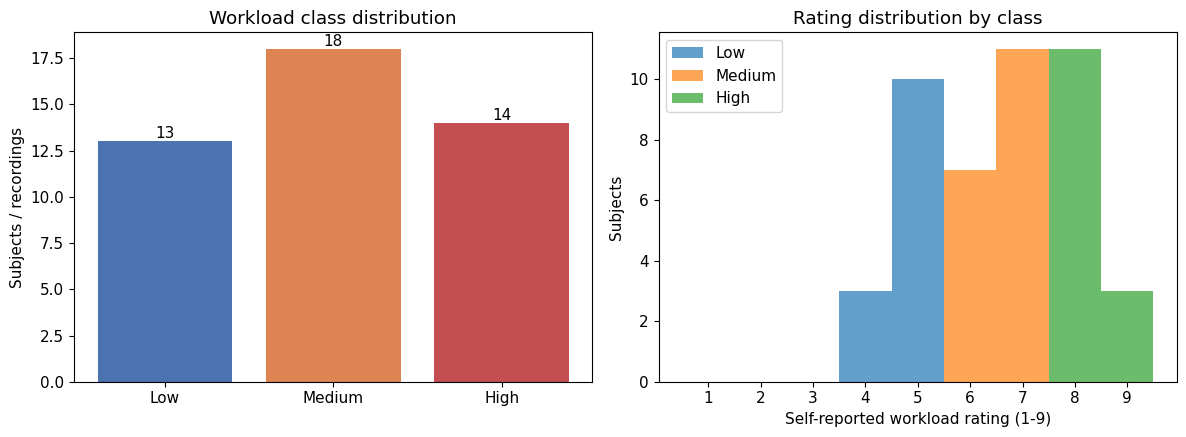

In [6]:
# ============================================================
# 6. FIGURE 1 — CLASS AND RATING DISTRIBUTION
# ============================================================
fig, axes = plt.subplots(1, 2 if "rating" in meta else 1, figsize=(12 if "rating" in meta else 6, 4.5))
axes = np.atleast_1d(axes)
cnt = meta["label_name"].value_counts().reindex(CLASS_NAMES)
axes[0].bar(cnt.index, cnt.values, color=["#4C72B0", "#DD8452", "#C44E52"][:N_CLASSES])
for i, v in enumerate(cnt.values): axes[0].text(i, v, str(v), ha="center", va="bottom")
axes[0].set_ylabel("Subjects / recordings"); axes[0].set_title("Workload class distribution")
if "rating" in meta:
    for k, name in enumerate(CLASS_NAMES):
        r = meta.loc[meta["label"] == k, "rating"]
        axes[1].hist(r, bins=np.arange(0.5, 10, 1), alpha=0.7, label=name)
    axes[1].set_xticks(range(1, 10)); axes[1].set_xlabel("Self-reported workload rating (1-9)")
    axes[1].set_ylabel("Subjects"); axes[1].set_title("Rating distribution by class"); axes[1].legend()
savefig("Fig01_class_rating_distribution.png")

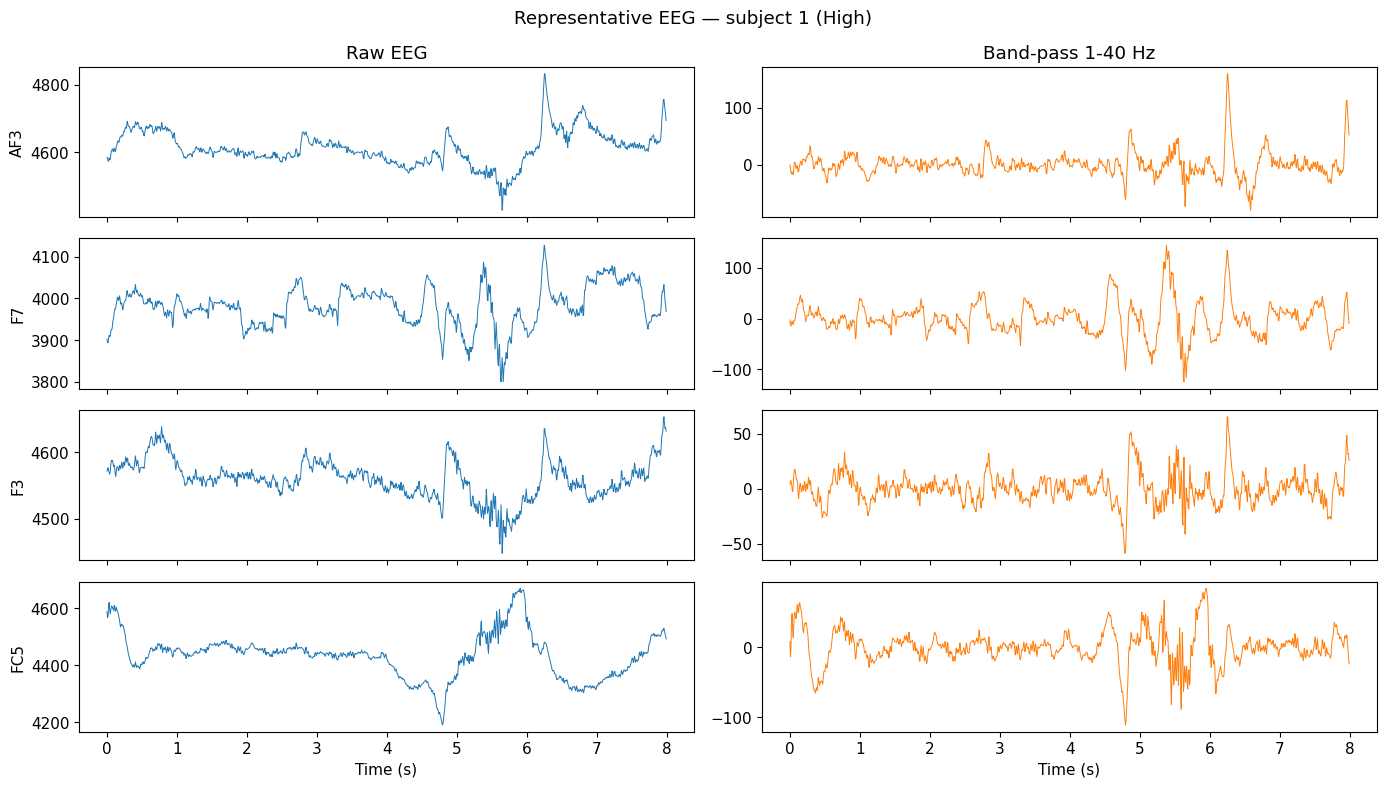

In [7]:
# ============================================================
# 7. PRE-PROCESSING + FIGURE 2 — RAW / FILTERED EEG
# ============================================================
SOS_BROAD = signal.butter(4, [LOWCUT, HIGHCUT], btype="bandpass", fs=FS, output="sos")
BANDS = {"delta": (1, 4), "theta": (4, 8), "alpha": (8, 13), "beta": (13, 30), "gamma": (30, 40)}
GRAPH_BANDS = {"theta": (4, 8), "alpha": (8, 13), "beta": (13, 30)}
SOS_BANDS = {b: signal.butter(4, r, btype="bandpass", fs=FS, output="sos") for b, r in GRAPH_BANDS.items()}

def bandpass(x, sos=SOS_BROAD):
    x = x - np.median(x, axis=0, keepdims=True)        # remove DC offset (Emotiv ~4000 uV)
    return signal.sosfiltfilt(sos, x, axis=0)

def robust_standardize(x):
    med = np.median(x, axis=0, keepdims=True)
    mad = 1.4826 * np.median(np.abs(x - med), axis=0, keepdims=True)
    mad[mad < 1e-6] = 1.0
    return (x - med) / mad

ex = int(meta.iloc[0]["rec_id"])
raw = eeg_list[ex]; filt = bandpass(raw)
n = min(len(raw), 8 * FS); t = np.arange(n) / FS
fig, axes = plt.subplots(4, 2, figsize=(14, 8), sharex=True)
for k in range(4):
    axes[k, 0].plot(t, raw[:n, k], lw=0.7); axes[k, 0].set_ylabel(CHANNELS[k])
    axes[k, 1].plot(t, filt[:n, k], lw=0.7, color="C1")
axes[0, 0].set_title("Raw EEG"); axes[0, 1].set_title(f"Band-pass {LOWCUT:.0f}-{HIGHCUT:.0f} Hz")
axes[-1, 0].set_xlabel("Time (s)"); axes[-1, 1].set_xlabel("Time (s)")
fig.suptitle(f"Representative EEG — subject {meta.iloc[0]['subject']} ({meta.iloc[0]['label_name']})")
savefig("Fig02_raw_vs_filtered_eeg.png")

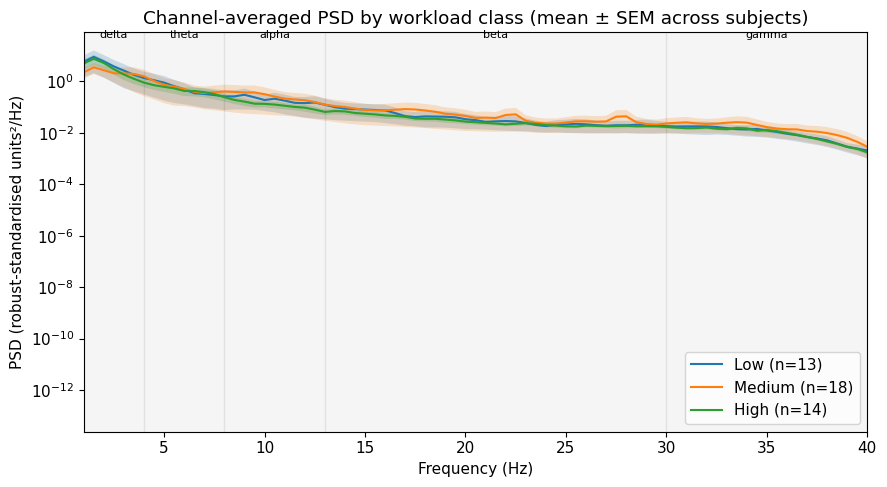

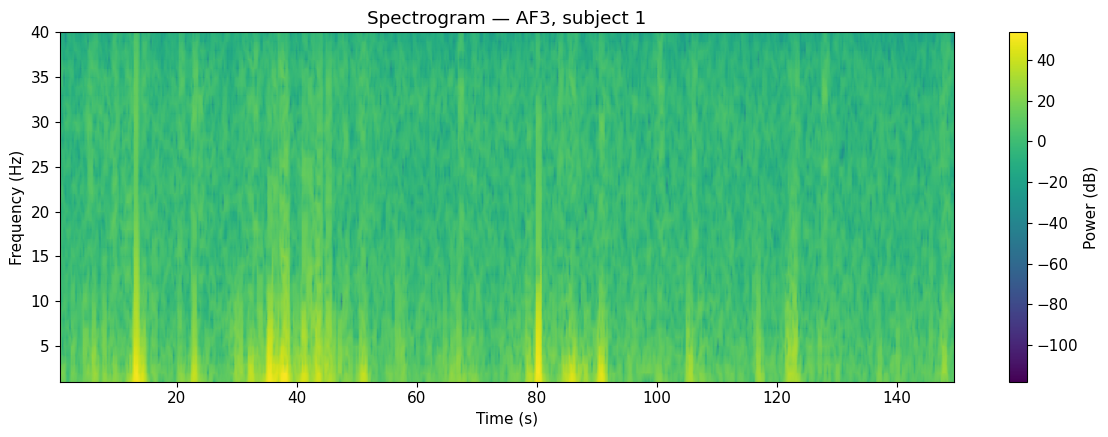

In [8]:
# ============================================================
# 8. FIGURE 3 — CLASS-AVERAGED PSD  |  FIGURE 4 — SPECTROGRAM
# ============================================================
psd_rows = []
for r in meta.itertuples():
    f_, p_ = signal.welch(robust_standardize(bandpass(eeg_list[r.rec_id])), fs=FS, nperseg=2 * FS, axis=0)
    psd_rows.append(p_.mean(1))
PSD = np.array(psd_rows)
plt.figure(figsize=(9, 5))
for k, name in enumerate(CLASS_NAMES):
    m = PSD[meta["label"].values == k]
    mu, se = m.mean(0), m.std(0, ddof=1) / np.sqrt(max(len(m), 1))
    plt.semilogy(f_, mu, label=f"{name} (n={len(m)})"); plt.fill_between(f_, mu - se, mu + se, alpha=0.2)
for b, (lo, hi) in BANDS.items():
    plt.axvspan(lo, hi, alpha=0.04, color="k"); plt.text((lo + hi) / 2, plt.ylim()[1] * 0.6, b, ha="center", fontsize=8)
plt.xlim(1, 40); plt.xlabel("Frequency (Hz)"); plt.ylabel("PSD (robust-standardised units²/Hz)")
plt.title("Channel-averaged PSD by workload class (mean ± SEM across subjects)"); plt.legend()
savefig("Fig03_psd_by_class.png")

fs_, ts_, sxx = signal.spectrogram(filt[:, 0], fs=FS, nperseg=128, noverlap=96)
plt.figure(figsize=(12, 4.5))
plt.pcolormesh(ts_, fs_, 10 * np.log10(sxx + 1e-12), shading="gouraud", cmap="viridis")
plt.ylim(1, 40); plt.xlabel("Time (s)"); plt.ylabel("Frequency (Hz)"); plt.colorbar(label="Power (dB)")
plt.title(f"Spectrogram — {CHANNELS[0]}, subject {meta.iloc[0]['subject']}")
savefig("Fig04_spectrogram.png")

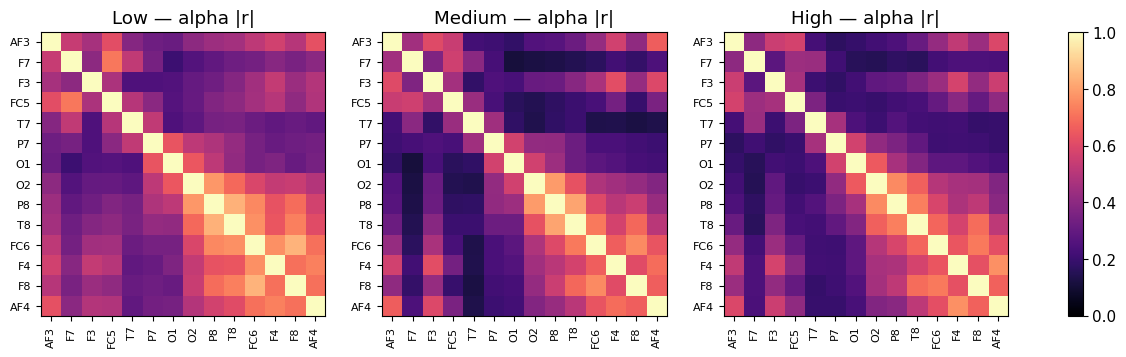

In [9]:
# ============================================================
# 9. FIGURE 5 — FUNCTIONAL CONNECTIVITY BY CLASS (alpha band)
# ============================================================
conn = {k: [] for k in CLASSES}
for r in meta.itertuples():
    xa = bandpass(eeg_list[r.rec_id], SOS_BANDS["alpha"])
    conn[r.label].append(np.abs(np.corrcoef(xa.T)))
fig, axes = plt.subplots(1, N_CLASSES, figsize=(5.2 * N_CLASSES, 4.6))
for k, ax in zip(CLASSES, np.atleast_1d(axes)):
    im = ax.imshow(np.mean(conn[k], 0), vmin=0, vmax=1, cmap="magma")
    ax.set_xticks(range(14)); ax.set_xticklabels(CHANNELS, rotation=90, fontsize=8)
    ax.set_yticks(range(14)); ax.set_yticklabels(CHANNELS, fontsize=8); ax.set_title(f"{CLASS_NAMES[k]} — alpha |r|")
plt.colorbar(im, ax=axes, shrink=0.8)
plt.savefig(f"{OUT}/Fig05_alpha_connectivity_by_class.png", dpi=300, bbox_inches="tight"); plt.show()

## 7. Window-level feature extraction (vectorised)
Each recording is filtered and robust-standardised **independently** (no cross-subject statistics → no leakage), then cut into 2-s windows with 1-s step.

Feature groups (used later in the ablation study):
* **Temporal / Hjorth** — mean, SD, RMS, peak-to-peak, line length, Hjorth activity / mobility / complexity (8 × 14)
* **Spectral** — relative δ θ α β γ power, θ/α and β/α ratios (7 × 14) + 3 frontal alpha-asymmetry indices
* **NeuroGraph** — band-limited (θ, α, β, broadband) functional-connectivity graphs per window: node strength (14) + mean connectivity, weighted clustering and global efficiency (3) per band

In [10]:
# ============================================================
# 10. FEATURE FUNCTIONS
# ============================================================
TEMPORAL = ["mean", "std", "rms", "ptp", "line_length", "hjorth_activity", "hjorth_mobility", "hjorth_complexity"]
SPECTRAL = [f"{b}_rel" for b in BANDS] + ["theta_alpha_ratio", "beta_alpha_ratio"]
ASYM_PAIRS = [("AF3", "AF4"), ("F3", "F4"), ("F7", "F8")]
GRAPH_SETS = list(GRAPH_BANDS) + ["broad"]

FEATURE_NAMES, FEATURE_GROUP, FEATURE_CHANNEL = [], [], []
for ch in CHANNELS:
    for f in TEMPORAL: FEATURE_NAMES.append(f"{ch}_{f}"); FEATURE_GROUP.append("Temporal"); FEATURE_CHANNEL.append(ch)
    for f in SPECTRAL: FEATURE_NAMES.append(f"{ch}_{f}"); FEATURE_GROUP.append("Spectral"); FEATURE_CHANNEL.append(ch)
for a, b in ASYM_PAIRS:
    FEATURE_NAMES.append(f"alpha_asym_{b}-{a}"); FEATURE_GROUP.append("Spectral"); FEATURE_CHANNEL.append("global")
for gb in GRAPH_SETS:
    for ch in CHANNELS:
        FEATURE_NAMES.append(f"{ch}_graph_{gb}_strength"); FEATURE_GROUP.append("NeuroGraph"); FEATURE_CHANNEL.append(ch)
    for g in ["mean_conn", "clustering", "global_eff"]:
        FEATURE_NAMES.append(f"graph_{gb}_{g}"); FEATURE_GROUP.append("NeuroGraph"); FEATURE_CHANNEL.append("global")
FEATURE_GROUP = np.array(FEATURE_GROUP); FEATURE_CHANNEL = np.array(FEATURE_CHANNEL)
print("Total features per window:", len(FEATURE_NAMES), pd.Series(FEATURE_GROUP).value_counts().to_dict())

def make_windows(x):
    """(samples, ch) -> (n_win, WINDOW, ch) view."""
    n_win = (len(x) - WINDOW) // STEP + 1
    if n_win <= 0:
        return np.empty((0, WINDOW, x.shape[1]))
    idx = np.arange(WINDOW)[None, :] + STEP * np.arange(n_win)[:, None]
    return x[idx]

def band_area(f, p, lo, hi):
    m = (f >= lo) & (f < hi)
    return np.trapezoid(p[..., m], f[m], axis=-1) if hasattr(np, "trapezoid") else np.trapz(p[..., m], f[m], axis=-1)

def graph_metrics(W):
    """W: (n_win, 14, 14) |correlation| matrices -> strength, mean conn, clustering, global efficiency."""
    n = W.shape[1]
    W = W.copy(); idx = np.arange(n); W[:, idx, idx] = 0.0
    strength = W.sum(2) / (n - 1)
    mean_conn = strength.mean(1)
    Wc = np.cbrt(W)                                         # Onnela weighted clustering (complete graph)
    cyc = np.einsum("wij,wjk,wki->wi", Wc, Wc, Wc)
    clustering = (cyc / ((n - 1) * (n - 2))).mean(1)
    D = 1.0 / np.clip(W, 1e-6, None); D[:, idx, idx] = 0.0  # Floyd-Warshall shortest paths
    for k in range(n):
        D = np.minimum(D, D[:, :, k:k + 1] + D[:, k:k + 1, :])
    inv = 1.0 / np.where(D > 0, D, np.inf)
    eff = inv.sum((1, 2)) / (n * (n - 1))
    return strength, mean_conn, clustering, eff

def window_corr(Xw):
    Z = Xw - Xw.mean(1, keepdims=True)
    Z = Z / (np.linalg.norm(Z, axis=1, keepdims=True) + 1e-12)
    return np.abs(np.einsum("wtc,wtd->wcd", Z, Z))

def extract_recording_features(x_raw):
    xb = robust_standardize(bandpass(x_raw))
    Wb = make_windows(xb)                                   # (n_win, T, C)
    if len(Wb) == 0:
        return np.empty((0, len(FEATURE_NAMES)), np.float32)
    s = np.transpose(Wb, (0, 2, 1))                         # (n_win, C, T)
    d1, d2 = np.diff(s, axis=2), np.diff(s, n=2, axis=2)
    v0, v1, v2 = s.var(2) + 1e-12, d1.var(2) + 1e-12, d2.var(2) + 1e-12
    mob = np.sqrt(v1 / v0); comp = np.sqrt(v2 / v1) / (mob + 1e-12)
    temporal = np.stack([s.mean(2), s.std(2), np.sqrt((s ** 2).mean(2)), np.ptp(s, axis=2),
                         np.abs(d1).sum(2), v0, mob, comp], axis=2)          # (n_win, C, 8)
    f, p = signal.welch(s, fs=FS, nperseg=WINDOW, axis=2)
    total = band_area(f, p, 1, 40) + 1e-12
    rel = {b: band_area(f, p, lo, hi) / total for b, (lo, hi) in BANDS.items()}
    spectral = np.stack([rel[b] for b in BANDS] + [rel["theta"] / (rel["alpha"] + 1e-12),
                                                   rel["beta"] / (rel["alpha"] + 1e-12)], axis=2)  # (n_win, C, 7)
    abs_alpha = band_area(f, p, 8, 13) + 1e-12
    asym = np.stack([np.log(abs_alpha[:, CHANNELS.index(b)]) - np.log(abs_alpha[:, CHANNELS.index(a)])
                     for a, b in ASYM_PAIRS], axis=1)
    per_ch = np.concatenate([temporal, spectral], axis=2).reshape(len(Wb), -1)
    graph = []
    for gb in GRAPH_SETS:
        xg = Wb if gb == "broad" else make_windows(robust_standardize(bandpass(x_raw, SOS_BANDS[gb])))
        st, mc, cl, ef = graph_metrics(window_corr(xg))
        graph += [st, mc[:, None], cl[:, None], ef[:, None]]
    return np.concatenate([per_ch, asym] + graph, axis=1).astype(np.float32)

Total features per window: 281 {'Temporal': 112, 'Spectral': 101, 'NeuroGraph': 68}


In [11]:
# ============================================================
# 11. BUILD FEATURE MATRIX
# ============================================================
t0 = time.time()
X_parts, y_parts, g_parts, r_parts = [], [], [], []
for r in meta.itertuples():
    F = extract_recording_features(eeg_list[r.rec_id])
    X_parts.append(F); y_parts.append(np.full(len(F), r.label))
    g_parts.append(np.full(len(F), r.subject)); r_parts.append(np.full(len(F), r.rec_id))
X = np.vstack(X_parts); y = np.concatenate(y_parts).astype(int)
groups = np.concatenate(g_parts).astype(int); rec_ids = np.concatenate(r_parts).astype(int)
bad = ~np.isfinite(X)
if bad.any():
    print("Replacing", int(bad.sum()), "non-finite feature values with column medians")
    X[bad] = np.take(np.nanmedian(np.where(bad, np.nan, X), 0), np.where(bad)[1])
print(f"Feature matrix {X.shape} built in {time.time()-t0:.1f}s | windows per class:",
      dict(zip(CLASS_NAMES, np.bincount(y, minlength=N_CLASSES))), "| subjects:", len(np.unique(groups)))
assert X.shape[1] == len(FEATURE_NAMES)
assert len(np.unique(y)) >= 2, "Only one class present — check the label section."

feature_summary = pd.DataFrame({"feature": FEATURE_NAMES, "group": FEATURE_GROUP, "mean": X.mean(0),
                                "std": X.std(0), "min": X.min(0), "max": X.max(0)})
feature_summary.to_csv(f"{OUT}/T02_feature_summary.csv", index=False)
display(feature_summary.head(10))

Feature matrix (6705, 281) built in 16.3s | windows per class: {'Low': np.int64(1937), 'Medium': np.int64(2682), 'High': np.int64(2086)} | subjects: 45


,feature,group,mean,std,min,max
0,AF3_mean,Temporal,0.042774,0.192512,-3.913279,3.949318
1,AF3_std,Temporal,1.565190,2.621356,0.178726,84.084946
2,AF3_rms,Temporal,1.569878,2.625966,0.179500,84.102371
3,AF3_ptp,Temporal,8.975390,17.987761,0.786713,586.261597
4,AF3_line_length,Temporal,101.618073,77.603355,19.693249,1973.495972
5,AF3_hjorth_activity,Temporal,9.321335,116.271248,0.031943,7070.277832
6,AF3_hjorth_mobility,Temporal,0.427953,0.153822,0.044072,1.159826
7,AF3_hjorth_complexity,Temporal,2.783645,0.966067,1.084699,13.201385
8,AF3_delta_rel,Spectral,0.507989,0.213524,0.020912,0.999220
9,AF3_theta_rel,Spectral,0.177052,0.113201,0.000328,0.867365


## 8. Subject-wise stratified cross-validation (main evaluation)
`StratifiedGroupKFold` — **no subject contributes windows to both training and test folds**. Scalers are fitted inside each training fold (Pipeline).
Window probabilities are also averaged per subject to give subject-level decisions.

In [12]:
# ============================================================
# 12. METRICS + MODELS
# ============================================================
def compute_metrics(y_true, y_pred, P):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    avg = "binary" if N_CLASSES == 2 else "macro"
    cm = confusion_matrix(y_true, y_pred, labels=CLASSES)
    spec = []
    for k in CLASSES:
        tn = cm.sum() - cm[k, :].sum() - cm[:, k].sum() + cm[k, k]; fp = cm[:, k].sum() - cm[k, k]
        spec.append(tn / (tn + fp) if (tn + fp) else np.nan)
    try:
        if N_CLASSES == 2:
            auc = roc_auc_score(y_true, P[:, 1]); pr = average_precision_score(y_true, P[:, 1])
        else:
            present = np.unique(y_true)
            Yb = label_binarize(y_true, classes=CLASSES)
            auc = np.mean([roc_auc_score(Yb[:, k], P[:, k]) for k in present if 0 < Yb[:, k].sum() < len(Yb)])
            pr = np.mean([average_precision_score(Yb[:, k], P[:, k]) for k in present if Yb[:, k].sum() > 0])
    except Exception:
        auc, pr = np.nan, np.nan
    return {"accuracy": accuracy_score(y_true, y_pred),
            "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
            "precision": precision_score(y_true, y_pred, average=avg, zero_division=0),
            "recall_sensitivity": recall_score(y_true, y_pred, average=avg, zero_division=0),
            "specificity": np.nanmean(spec) if N_CLASSES > 2 else spec[0],
            "f1": f1_score(y_true, y_pred, average=avg, zero_division=0),
            "mcc": matthews_corrcoef(y_true, y_pred),
            "kappa": cohen_kappa_score(y_true, y_pred),
            "auc": auc, "pr_auc": pr}

def predict_proba_full(model, Xt):
    P = model.predict_proba(Xt)
    out = np.zeros((len(Xt), N_CLASSES)); out[:, list(model.classes_)] = P
    return out

def make_models():
    lr = Pipeline([("s", StandardScaler()), ("m", LogisticRegression(max_iter=3000, C=0.5, class_weight="balanced", random_state=SEED))])
    svm = Pipeline([("s", StandardScaler()), ("m", SVC(C=2.0, kernel="rbf", probability=True, class_weight="balanced", random_state=SEED))])
    et = ExtraTreesClassifier(n_estimators=300, min_samples_leaf=2, max_features="sqrt", class_weight="balanced", random_state=SEED, n_jobs=-1)
    hgb = HistGradientBoostingClassifier(max_iter=250, learning_rate=0.05, max_leaf_nodes=31, l2_regularization=1.0,
                                         class_weight="balanced", random_state=SEED)
    return {
        "LogisticRegression": lr,
        "SVM_RBF": svm,
        "RandomForest": RandomForestClassifier(n_estimators=300, min_samples_leaf=2, class_weight="balanced", random_state=SEED, n_jobs=-1),
        "ExtraTrees": et,
        "HistGradientBoosting": hgb,
        "MLP": Pipeline([("s", StandardScaler()), ("m", MLPClassifier(hidden_layer_sizes=(128, 64), alpha=1e-3, early_stopping=True,
                                                                       max_iter=300, random_state=SEED))]),
        # Proposed: soft-voting ensemble over all three feature families (temporal + spectral + NeuroGraph)
        "NeuroGraph-Ensemble": VotingClassifier([("lr", clone(lr)), ("svm", clone(svm)), ("et", clone(et)), ("hgb", clone(hgb))],
                                                voting="soft", n_jobs=1),
    }

models = make_models()
subj_lab = pd.Series(y, index=groups).groupby(level=0).first()
n_splits = int(min(N_FOLDS, subj_lab.value_counts().min()))
assert n_splits >= 2, f"Need at least 2 subjects per class, got {subj_lab.value_counts().to_dict()}"
CV = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=SEED)
FOLDS = list(CV.split(X, y, groups))
for i, (tr, te) in enumerate(FOLDS, 1):
    assert not set(groups[tr]) & set(groups[te]), "Subject leakage detected!"
    print(f"Fold {i}: train subjects={len(set(groups[tr]))}, test subjects={len(set(groups[te]))}, "
          f"test classes={np.bincount(y[te], minlength=N_CLASSES).tolist()}")
print("Leakage check passed: no subject appears in both train and test.")

Fold 1: train subjects=36, test subjects=9, test classes=[447, 298, 596]
Fold 2: train subjects=36, test subjects=9, test classes=[298, 447, 596]
Fold 3: train subjects=36, test subjects=9, test classes=[596, 298, 447]
Fold 4: train subjects=36, test subjects=9, test classes=[447, 745, 149]
Fold 5: train subjects=36, test subjects=9, test classes=[149, 894, 298]
Leakage check passed: no subject appears in both train and test.


In [13]:
# ============================================================
# 13. RUN CROSS-VALIDATION FOR ALL MODELS
# ============================================================
def subject_aggregate(P, idx=None):
    idx = np.arange(len(y)) if idx is None else idx
    df = pd.DataFrame(P[idx], columns=CLASSES); df["subject"] = groups[idx]; df["true"] = y[idx]
    agg = df.groupby("subject").mean()
    return agg["true"].astype(int).values, agg[CLASSES].values, agg.index.values

results, oof = [], {}
for name, base in models.items():
    t0 = time.time(); P_oof = np.full((len(y), N_CLASSES), np.nan)
    for fold, (tr, te) in enumerate(FOLDS, 1):
        m = clone(base).fit(X[tr], y[tr])
        P = predict_proba_full(m, X[te]); P_oof[te] = P
        row = {"model": name, "fold": fold, "train_subjects": len(set(groups[tr])), "test_subjects": len(set(groups[te])),
               "test_windows": len(te), **compute_metrics(y[te], P.argmax(1), P)}
        st, sP, _ = subject_aggregate(P_oof, te)
        row["subject_accuracy"] = accuracy_score(st, sP.argmax(1))
        results.append(row)
    oof[name] = P_oof
    r = pd.DataFrame(results).query("model == @name")
    print(f"{name:22s} F1={r.f1.mean():.3f}±{r.f1.std():.3f}  Acc={r.accuracy.mean():.3f}  AUC={r.auc.mean():.3f}  "
          f"subj-Acc={r.subject_accuracy.mean():.3f}  ({time.time()-t0:.0f}s)")
results_df = pd.DataFrame(results)
results_df.to_csv(f"{OUT}/T03_fold_results.csv", index=False)

LogisticRegression     F1=0.362±0.101  Acc=0.394  AUC=0.571  subj-Acc=0.444  (20s)
SVM_RBF                F1=0.364±0.090  Acc=0.386  AUC=0.593  subj-Acc=0.422  (95s)
RandomForest           F1=0.373±0.073  Acc=0.409  AUC=0.638  subj-Acc=0.444  (145s)
ExtraTrees             F1=0.357±0.079  Acc=0.399  AUC=0.618  subj-Acc=0.400  (20s)
HistGradientBoosting   F1=0.367±0.058  Acc=0.399  AUC=0.611  subj-Acc=0.378  (171s)
MLP                    F1=0.333±0.086  Acc=0.353  AUC=0.552  subj-Acc=0.378  (14s)
NeuroGraph-Ensemble    F1=0.360±0.074  Acc=0.394  AUC=0.610  subj-Acc=0.356  (295s)


In [14]:
# ============================================================
# 14. MODEL SUMMARY TABLE (mean ± SD across subject-wise folds)
# ============================================================
metric_cols = ["accuracy", "balanced_accuracy", "precision", "recall_sensitivity", "specificity", "f1", "mcc", "kappa", "auc", "pr_auc", "subject_accuracy"]
model_summary = results_df.groupby("model")[metric_cols].agg(["mean", "std"])
model_summary.columns = [f"{a}_{b}" for a, b in model_summary.columns]
model_summary = model_summary.sort_values("f1_mean", ascending=False)
pretty = pd.DataFrame({m: [f"{model_summary.loc[i, m+'_mean']:.3f} ± {model_summary.loc[i, m+'_std']:.3f}" for i in model_summary.index]
                       for m in metric_cols}, index=model_summary.index)
display(pretty)
model_summary.to_csv(f"{OUT}/T04_model_summary.csv"); pretty.to_csv(f"{OUT}/T04_model_summary_formatted.csv")

best_name = model_summary.index[0]
P_best = oof[best_name]; pred_best = P_best.argmax(1)
print("Best model (mean fold F1):", best_name)

,accuracy,balanced_accuracy,precision,recall_sensitivity,specificity,f1,mcc,kappa,auc,pr_auc,subject_accuracy
model,,,,,,,,,,,
RandomForest,0.409 ± 0.077,0.436 ± 0.049,0.416 ± 0.056,0.436 ± 0.049,0.716 ± 0.031,0.373 ± 0.073,0.149 ± 0.069,0.131 ± 0.067,0.638 ± 0.051,0.430 ± 0.055,0.444 ± 0.079
HistGradientBoosting,0.399 ± 0.063,0.414 ± 0.061,0.407 ± 0.072,0.414 ± 0.061,0.705 ± 0.038,0.367 ± 0.058,0.119 ± 0.107,0.104 ± 0.097,0.611 ± 0.075,0.410 ± 0.065,0.378 ± 0.099
SVM_RBF,0.386 ± 0.086,0.420 ± 0.063,0.398 ± 0.090,0.420 ± 0.063,0.704 ± 0.043,0.364 ± 0.090,0.112 ± 0.118,0.103 ± 0.106,0.593 ± 0.078,0.405 ± 0.076,0.422 ± 0.145
LogisticRegression,0.394 ± 0.101,0.384 ± 0.099,0.390 ± 0.097,0.384 ± 0.099,0.701 ± 0.052,0.362 ± 0.101,0.094 ± 0.148,0.089 ± 0.138,0.571 ± 0.092,0.397 ± 0.080,0.444 ± 0.192
NeuroGraph-Ensemble,0.394 ± 0.079,0.410 ± 0.045,0.395 ± 0.080,0.410 ± 0.045,0.707 ± 0.042,0.360 ± 0.074,0.116 ± 0.104,0.105 ± 0.095,0.610 ± 0.066,0.410 ± 0.066,0.356 ± 0.122
ExtraTrees,0.399 ± 0.081,0.421 ± 0.043,0.394 ± 0.068,0.421 ± 0.043,0.711 ± 0.032,0.357 ± 0.079,0.130 ± 0.072,0.114 ± 0.070,0.618 ± 0.050,0.417 ± 0.053,0.400 ± 0.127
MLP,0.353 ± 0.081,0.383 ± 0.068,0.370 ± 0.086,0.383 ± 0.068,0.687 ± 0.044,0.333 ± 0.086,0.065 ± 0.121,0.061 ± 0.109,0.552 ± 0.082,0.375 ± 0.075,0.378 ± 0.149


Best model (mean fold F1): RandomForest


## 9. Diagnostic figures for the best model (out-of-fold predictions)

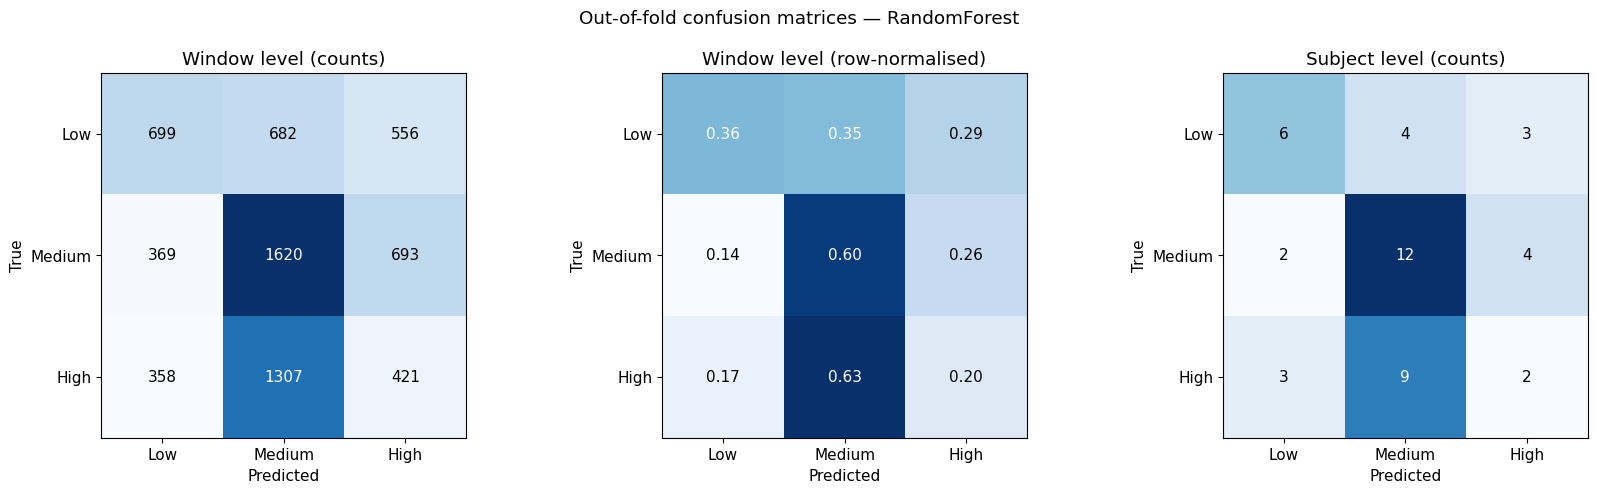

In [15]:
# ============================================================
# 15. FIGURE 6 — CONFUSION MATRICES (window + subject level)
# ============================================================
st, sP, s_ids = subject_aggregate(P_best)
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, (cm, title, fmt) in zip(axes, [
        (confusion_matrix(y, pred_best, labels=CLASSES), "Window level (counts)", "d"),
        (confusion_matrix(y, pred_best, labels=CLASSES, normalize="true"), "Window level (row-normalised)", ".2f"),
        (confusion_matrix(st, sP.argmax(1), labels=CLASSES), "Subject level (counts)", "d")]):
    im = ax.imshow(cm, cmap="Blues")
    for i in range(N_CLASSES):
        for j in range(N_CLASSES):
            ax.text(j, i, format(cm[i, j], fmt), ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks(CLASSES); ax.set_xticklabels(CLASS_NAMES); ax.set_yticks(CLASSES); ax.set_yticklabels(CLASS_NAMES)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(title)
fig.suptitle(f"Out-of-fold confusion matrices — {best_name}")
savefig("Fig06_confusion_matrices.png")

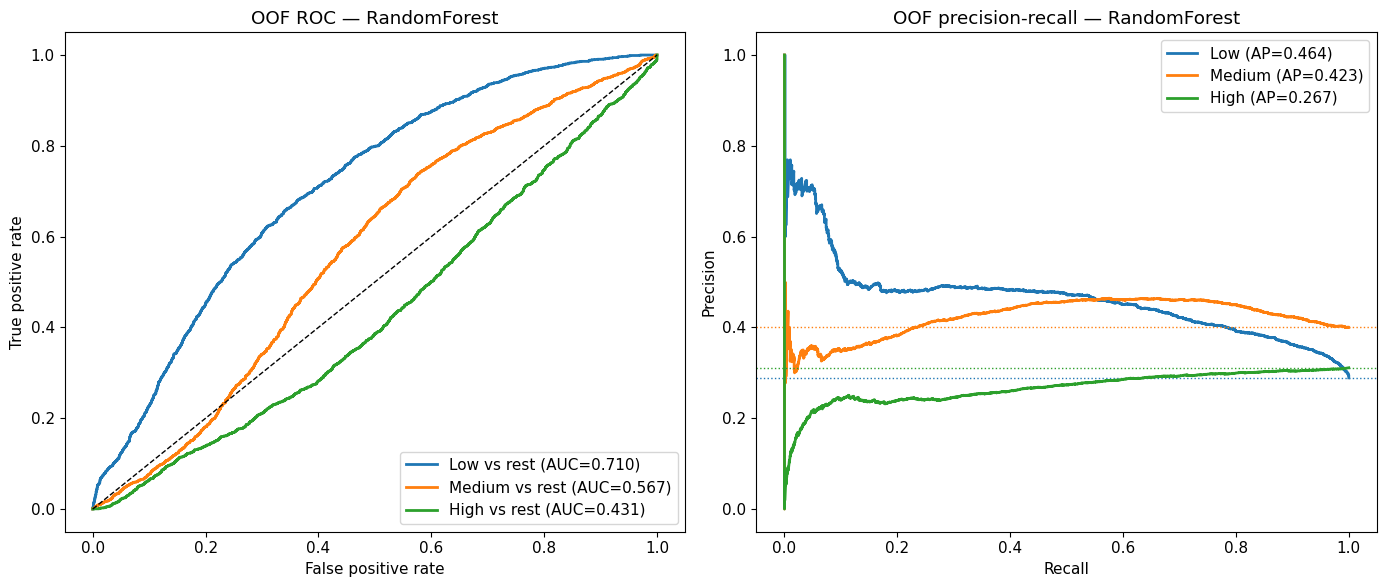

In [16]:
# ============================================================
# 16. FIGURE 7 — ROC  |  FIGURE 8 — PRECISION-RECALL (one-vs-rest)
# ============================================================
Yb = label_binarize(y, classes=CLASSES) if N_CLASSES > 2 else np.c_[1 - y, y]
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for k in (CLASSES if N_CLASSES > 2 else [1]):
    fpr, tpr, _ = roc_curve(Yb[:, k], P_best[:, k]); a = roc_auc_score(Yb[:, k], P_best[:, k])
    axes[0].plot(fpr, tpr, lw=2, label=f"{CLASS_NAMES[k]} vs rest (AUC={a:.3f})")
    pr_, rc_, _ = precision_recall_curve(Yb[:, k], P_best[:, k]); ap = average_precision_score(Yb[:, k], P_best[:, k])
    axes[1].plot(rc_, pr_, lw=2, label=f"{CLASS_NAMES[k]} (AP={ap:.3f})")
    axes[1].axhline(Yb[:, k].mean(), ls=":", lw=1, color=axes[1].lines[-1].get_color())
axes[0].plot([0, 1], [0, 1], "k--", lw=1); axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate")
axes[0].set_title(f"OOF ROC — {best_name}"); axes[0].legend(loc="lower right")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision"); axes[1].set_title(f"OOF precision-recall — {best_name}"); axes[1].legend()
savefig("Fig07_08_ROC_PR_curves.png")

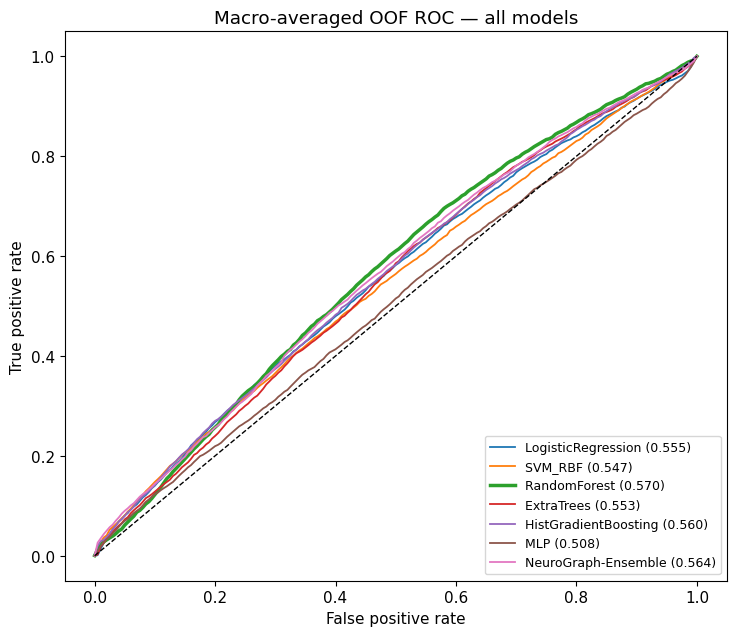

In [17]:
# ============================================================
# 17. FIGURE 9 — ROC OF ALL MODELS (macro one-vs-rest)
# ============================================================
plt.figure(figsize=(7.5, 6.5))
grid = np.linspace(0, 1, 201)
for name, P in oof.items():
    tprs = []
    for k in (CLASSES if N_CLASSES > 2 else [1]):
        fpr, tpr, _ = roc_curve(Yb[:, k], P[:, k]); tprs.append(np.interp(grid, fpr, tpr))
    auc_macro = compute_metrics(y, P.argmax(1), P)["auc"]
    plt.plot(grid, np.mean(tprs, 0), lw=2.5 if name == best_name else 1.3, label=f"{name} ({auc_macro:.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=1); plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("Macro-averaged OOF ROC — all models"); plt.legend(fontsize=9, loc="lower right")
savefig("Fig09_ROC_all_models.png")

In [18]:
# ============================================================
# 18. SUBJECT-LEVEL RESULTS + BOOTSTRAP 95% CIs (resampling subjects)
# ============================================================
subject_oof = pd.DataFrame(sP, columns=[f"P_{c}" for c in CLASS_NAMES])
subject_oof.insert(0, "subject", s_ids); subject_oof.insert(1, "true", [CLASS_NAMES[i] for i in st])
subject_oof["predicted"] = [CLASS_NAMES[i] for i in sP.argmax(1)]
subject_oof["correct"] = (st == sP.argmax(1)).astype(int)
subject_oof["n_windows"] = pd.Series(groups).value_counts().reindex(s_ids).values
display(subject_oof.head(15))
subject_oof.to_csv(f"{OUT}/T05_subject_level_oof.csv", index=False)

def bootstrap_ci(fn, n_boot=N_BOOT, seed=SEED):
    """Cluster bootstrap: resample subjects, keep all their windows."""
    rng = np.random.default_rng(seed); subj = np.unique(groups)
    by_s = {s: np.where(groups == s)[0] for s in subj}; vals = []
    for _ in range(n_boot):
        idx = np.concatenate([by_s[s] for s in rng.choice(subj, len(subj), replace=True)])
        if len(np.unique(y[idx])) < N_CLASSES:
            continue
        vals.append(fn(idx))
    return np.percentile(vals, [2.5, 97.5]) if vals else (np.nan, np.nan)

ci_rows = []
for name in model_summary.index:
    P = oof[name]; pr = P.argmax(1); m = compute_metrics(y, pr, P)
    sT, sPP, _ = subject_aggregate(P)
    row = {"model": name}
    for key, fn in [("accuracy", lambda i: accuracy_score(y[i], pr[i])),
                    ("f1", lambda i: f1_score(y[i], pr[i], average="macro" if N_CLASSES > 2 else "binary")),
                    ("auc", lambda i: compute_metrics(y[i], pr[i], P[i])["auc"])]:
        lo, hi = bootstrap_ci(fn, n_boot=N_BOOT if name == best_name else 500)
        row[f"{key}"] = m[key]; row[f"{key}_CI"] = f"[{lo:.3f}, {hi:.3f}]"
    row["subject_accuracy"] = accuracy_score(sT, sPP.argmax(1))
    row["subject_f1"] = f1_score(sT, sPP.argmax(1), average="macro" if N_CLASSES > 2 else "binary")
    ci_rows.append(row)
ci_df = pd.DataFrame(ci_rows).round(4)
display(ci_df)
ci_df.to_csv(f"{OUT}/T06_pooled_oof_metrics_with_CI.csv", index=False)

,subject,true,P_Low,P_Medium,P_High,predicted,correct,n_windows
0,1,High,0.206570,0.546894,0.246536,Medium,0,149
1,2,Low,0.295144,0.369665,0.335191,Medium,0,149
2,3,Low,0.301918,0.526700,0.171382,Medium,0,149
3,4,Low,0.294778,0.262269,0.442953,High,0,149
4,5,Medium,0.260771,0.361260,0.377969,High,0,149
5,6,Low,0.266824,0.567565,0.165611,Medium,0,149
6,7,Medium,0.169234,0.449837,0.380929,Medium,1,149
7,8,Medium,0.477144,0.167856,0.354999,Low,0,149
8,9,Medium,0.120738,0.538169,0.341093,Medium,1,149
9,10,Low,0.194373,0.227065,0.578562,High,0,149


,model,accuracy,accuracy_CI,f1,f1_CI,auc,auc_CI,subject_accuracy,subject_f1
0,RandomForest,0.4087,"[0.312, 0.508]",0.3850,"[0.289, 0.472]",0.5695,"[0.484, 0.659]",0.4444,0.4107
1,HistGradientBoosting,0.3993,"[0.301, 0.499]",0.3869,"[0.281, 0.470]",0.5596,"[0.463, 0.654]",0.3778,0.3420
2,SVM_RBF,0.3863,"[0.300, 0.472]",0.3784,"[0.287, 0.454]",0.5466,"[0.456, 0.626]",0.4222,0.4113
3,LogisticRegression,0.3939,"[0.306, 0.481]",0.3888,"[0.298, 0.472]",0.5545,"[0.467, 0.640]",0.4444,0.4461
4,NeuroGraph-Ensemble,0.3940,"[0.299, 0.491]",0.3799,"[0.285, 0.460]",0.5643,"[0.470, 0.653]",0.3556,0.3230
5,ExtraTrees,0.3994,"[0.303, 0.491]",0.3709,"[0.280, 0.449]",0.5526,"[0.462, 0.642]",0.4000,0.3428
6,MLP,0.3533,"[0.272, 0.437]",0.3488,"[0.260, 0.425]",0.5076,"[0.418, 0.594]",0.3778,0.3513


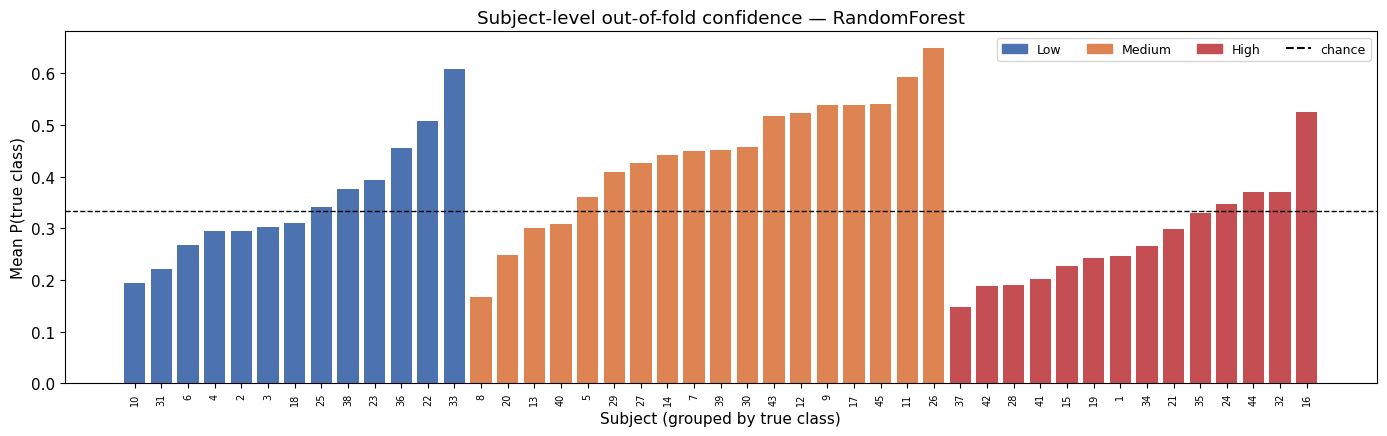

In [19]:
# ============================================================
# 19. FIGURE 10 — SUBJECT-WISE PROBABILITY OF TRUE CLASS
# ============================================================
p_true = sP[np.arange(len(st)), st]
order = np.lexsort((p_true, st))
plt.figure(figsize=(14, 4.5))
cols = np.array(["#4C72B0", "#DD8452", "#C44E52", "#55A868", "#8172B2"])[st[order]]
plt.bar(range(len(order)), p_true[order], color=cols)
plt.axhline(1 / N_CLASSES, ls="--", color="k", lw=1, label="chance")
plt.xticks(range(len(order)), s_ids[order], rotation=90, fontsize=7)
plt.xlabel("Subject (grouped by true class)"); plt.ylabel("Mean P(true class)")
plt.title(f"Subject-level out-of-fold confidence — {best_name}")
from matplotlib.patches import Patch
plt.legend(handles=[Patch(color=c, label=n) for c, n in zip(["#4C72B0", "#DD8452", "#C44E52"], CLASS_NAMES)] +
           [plt.Line2D([], [], ls="--", color="k", label="chance")], ncol=4, fontsize=9)
savefig("Fig10_subject_confidence.png")

## 10. Statistical model comparison and significance

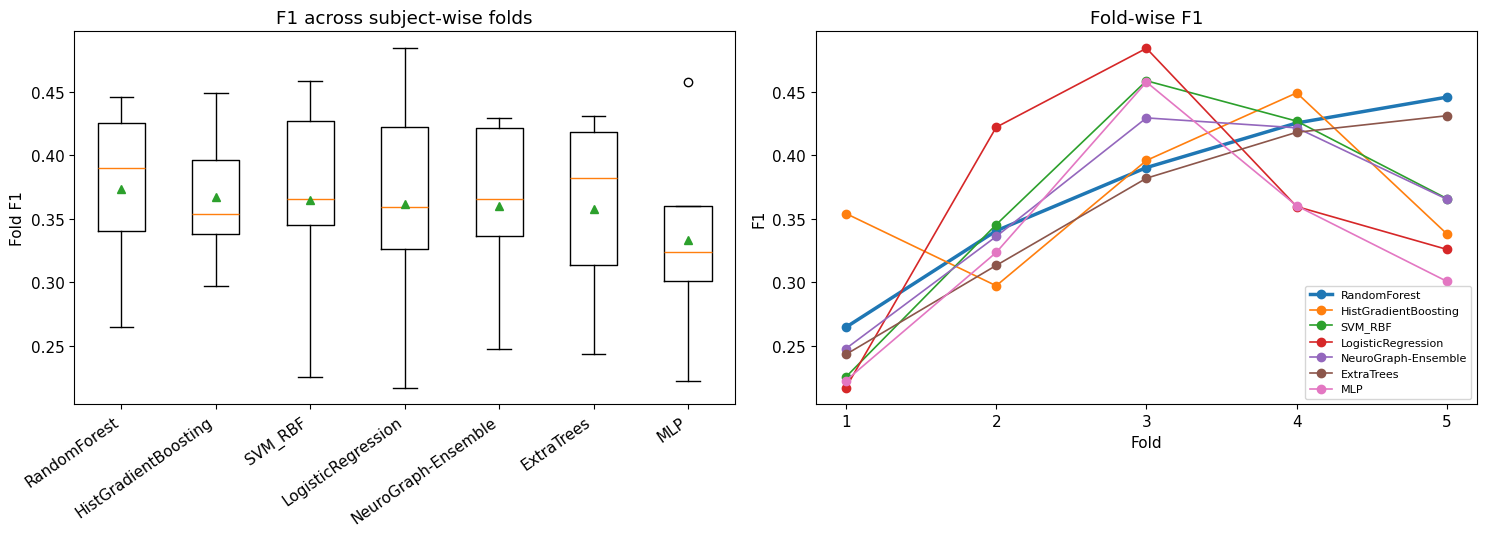

Friedman test across 7 models x 5 folds: chi2=5.657, p=0.4627
Average rank (1 = best):


,mean_rank
model,
SVM_RBF,2.8
RandomForest,3.0
HistGradientBoosting,3.8
NeuroGraph-Ensemble,3.8
LogisticRegression,4.4
ExtraTrees,4.8
MLP,5.4


,comparison,mean_F1_diff,wilcoxon_p,p_holm
0,RandomForest vs HistGradientBoosting,0.0064,1.0000,1.000
1,RandomForest vs SVM_RBF,0.0089,1.0000,1.000
2,RandomForest vs LogisticRegression,0.0115,1.0000,1.000
3,RandomForest vs NeuroGraph-Ensemble,0.0133,0.4375,1.000
4,RandomForest vs ExtraTrees,0.0158,0.0625,0.375
5,RandomForest vs MLP,0.0404,0.4375,1.000


Note: with 5 folds the smallest possible two-sided Wilcoxon p is 0.0625; report fold-level tests as descriptive.


In [20]:
# ============================================================
# 20. FIGURE 11 — FOLD-WISE F1  +  FRIEDMAN / WILCOXON TESTS
# ============================================================
fold_f1 = results_df.pivot(index="fold", columns="model", values="f1")[model_summary.index]
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
axes[0].boxplot([fold_f1[c] for c in fold_f1.columns], showmeans=True)
axes[0].set_xticks(range(1, fold_f1.shape[1] + 1)); axes[0].set_xticklabels(fold_f1.columns, rotation=35, ha="right"); axes[0].set_ylabel("Fold F1"); axes[0].set_title("F1 across subject-wise folds")
for c in fold_f1.columns:
    axes[1].plot(fold_f1.index, fold_f1[c], marker="o", lw=2.5 if c == best_name else 1.2, label=c)
axes[1].set_xticks(fold_f1.index); axes[1].set_xlabel("Fold"); axes[1].set_ylabel("F1"); axes[1].set_title("Fold-wise F1")
axes[1].legend(fontsize=8)
savefig("Fig11_foldwise_f1.png")

fr = stats.friedmanchisquare(*[fold_f1[c].values for c in fold_f1.columns])
ranks = fold_f1.rank(axis=1, ascending=False).mean().sort_values()
print(f"Friedman test across {fold_f1.shape[1]} models x {fold_f1.shape[0]} folds: chi2={fr.statistic:.3f}, p={fr.pvalue:.4g}")
print("Average rank (1 = best):"); display(ranks.round(2).to_frame("mean_rank"))
cmp_rows = []
for c in fold_f1.columns:
    if c == best_name: continue
    d = fold_f1[best_name] - fold_f1[c]
    try: w = stats.wilcoxon(fold_f1[best_name], fold_f1[c]); p = w.pvalue
    except ValueError: p = np.nan
    cmp_rows.append({"comparison": f"{best_name} vs {c}", "mean_F1_diff": d.mean(), "wilcoxon_p": p})
cmp_df = pd.DataFrame(cmp_rows)
def holm(p):
    p = np.asarray(p, float); n = len(p); o = np.argsort(p)
    adj = np.maximum.accumulate(p[o] * (n - np.arange(n)))
    out = np.empty(n); out[o] = np.minimum(adj, 1); return out
cmp_df["p_holm"] = holm(cmp_df.wilcoxon_p.fillna(1))
display(cmp_df.round(4))
print(f"Note: with {n_splits} folds the smallest possible two-sided Wilcoxon p is {2/2**n_splits:.4f}; report fold-level tests as descriptive.")
pd.concat([ranks.to_frame("mean_rank").reset_index().rename(columns={"index": "model"}), cmp_df], axis=1).to_csv(
    f"{OUT}/T07_model_comparison_tests.csv", index=False)

ExtraTrees observed macro-F1=0.374; permutation mean=0.281±0.056; p=0.0952 (20 permutations, 205s)


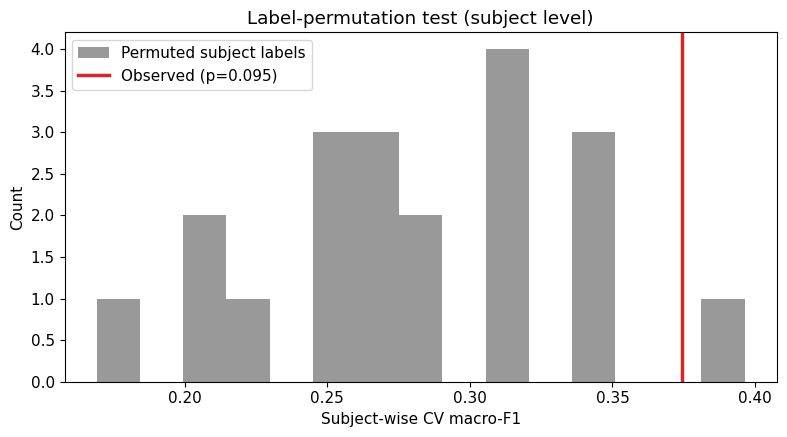

In [21]:
# ============================================================
# 21. FIGURE 12 — SUBJECT-LEVEL LABEL-PERMUTATION TEST
# ============================================================
def cv_macro_f1(labels_by_subject, model_factory, cols=None):
    yy = pd.Series(groups).map(labels_by_subject).values.astype(int)
    Xc = X if cols is None else X[:, cols]
    cv = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=SEED)
    P = np.zeros((len(yy), N_CLASSES))
    for tr, te in cv.split(Xc, yy, groups):
        m = model_factory().fit(Xc[tr], yy[tr]); P[te] = predict_proba_full(m, Xc[te])
    return f1_score(yy, P.argmax(1), average="macro"), P

fast_et = lambda: ExtraTreesClassifier(n_estimators=150, min_samples_leaf=2, class_weight="balanced", random_state=SEED, n_jobs=-1)
true_map = subj_lab.to_dict()
obs_f1, _ = cv_macro_f1(true_map, fast_et)
rng = np.random.default_rng(SEED); perm_f1 = []
t0 = time.time()
for i in range(N_PERMUTATIONS):
    perm = dict(zip(subj_lab.index, rng.permutation(subj_lab.values)))   # permute labels across SUBJECTS
    perm_f1.append(cv_macro_f1(perm, fast_et)[0])
perm_f1 = np.array(perm_f1)
p_perm = (np.sum(perm_f1 >= obs_f1) + 1) / (N_PERMUTATIONS + 1)
print(f"ExtraTrees observed macro-F1={obs_f1:.3f}; permutation mean={perm_f1.mean():.3f}±{perm_f1.std():.3f}; "
      f"p={p_perm:.4f} ({N_PERMUTATIONS} permutations, {time.time()-t0:.0f}s)")
plt.figure(figsize=(8, 4.5))
plt.hist(perm_f1, bins=15, color="grey", alpha=0.8, label="Permuted subject labels")
plt.axvline(obs_f1, color="C3", lw=2.5, label=f"Observed (p={p_perm:.3f})")
plt.xlabel("Subject-wise CV macro-F1"); plt.ylabel("Count"); plt.title("Label-permutation test (subject level)"); plt.legend()
savefig("Fig12_permutation_test.png")
pd.DataFrame({"perm_f1": perm_f1}).assign(observed=obs_f1, p_value=p_perm).to_csv(f"{OUT}/T08_permutation_test.csv", index=False)

## 11. Ablation study — contribution of each feature family

,n_features,f1_mean,f1_std,acc_mean,auc_mean,mcc_mean
feature_set,,,,,,
Temporal only,112,0.3263,0.0757,0.3521,0.5858,0.0850
Spectral only,101,0.3383,0.0837,0.3632,0.5740,0.0863
NeuroGraph only,68,0.3368,0.0813,0.3831,0.5816,0.0767
Temporal + Spectral,213,0.3309,0.0863,0.3563,0.5867,0.0892
Spectral + NeuroGraph,169,0.3536,0.0805,0.3948,0.6096,0.1095
All (Temporal + Spectral + NeuroGraph),281,0.3606,0.0788,0.4009,0.6187,0.1320


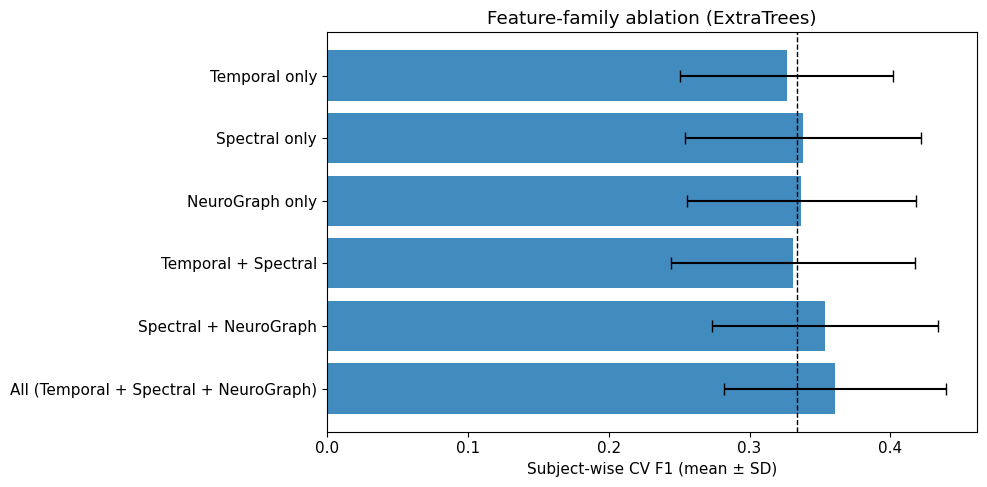

In [22]:
# ============================================================
# 22. FIGURE 13 — FEATURE-GROUP ABLATION
# ============================================================
ablation_sets = {
    "Temporal only": FEATURE_GROUP == "Temporal",
    "Spectral only": FEATURE_GROUP == "Spectral",
    "NeuroGraph only": FEATURE_GROUP == "NeuroGraph",
    "Temporal + Spectral": np.isin(FEATURE_GROUP, ["Temporal", "Spectral"]),
    "Spectral + NeuroGraph": np.isin(FEATURE_GROUP, ["Spectral", "NeuroGraph"]),
    "All (Temporal + Spectral + NeuroGraph)": np.ones(len(FEATURE_NAMES), bool),
}
abl_rows = []
for nm, mask in ablation_sets.items():
    cols = np.where(mask)[0]
    for fold, (tr, te) in enumerate(FOLDS, 1):
        m = fast_et().fit(X[tr][:, cols], y[tr]); P = predict_proba_full(m, X[te][:, cols])
        abl_rows.append({"feature_set": nm, "n_features": len(cols), "fold": fold, **compute_metrics(y[te], P.argmax(1), P)})
abl_df = pd.DataFrame(abl_rows)
abl_sum = abl_df.groupby("feature_set", sort=False).agg(n_features=("n_features", "first"), f1_mean=("f1", "mean"), f1_std=("f1", "std"),
                                                          acc_mean=("accuracy", "mean"), auc_mean=("auc", "mean"), mcc_mean=("mcc", "mean"))
display(abl_sum.round(4)); abl_sum.to_csv(f"{OUT}/T09_ablation.csv")
plt.figure(figsize=(10, 5))
plt.barh(abl_sum.index, abl_sum.f1_mean, xerr=abl_sum.f1_std, color="C0", alpha=0.85, capsize=4)
plt.axvline(1 / N_CLASSES, ls="--", color="k", lw=1); plt.xlabel("Subject-wise CV F1 (mean ± SD)")
plt.title("Feature-family ablation (ExtraTrees)"); plt.gca().invert_yaxis()
savefig("Fig13_ablation.png")

## 12. Explainability
* Impurity importance (ExtraTrees fitted on all data — descriptive)
* **Grouped permutation importance computed on held-out subjects** in every fold (drop in macro-F1 when a channel's / family's features are shuffled)

,feature,group,channel,importance
249,F3_graph_beta_strength,NeuroGraph,F3,0.021278
66,T7_hjorth_mobility,Temporal,T7,0.013821
232,F3_graph_alpha_strength,NeuroGraph,F3,0.013552
266,F3_graph_broad_strength,NeuroGraph,F3,0.011666
71,T7_beta_rel,Spectral,T7,0.010688
255,P8_graph_beta_strength,NeuroGraph,P8,0.010670
215,F3_graph_theta_strength,NeuroGraph,F3,0.010211
64,T7_line_length,Temporal,T7,0.009293
68,T7_delta_rel,Spectral,T7,0.009100
250,FC5_graph_beta_strength,NeuroGraph,FC5,0.008591


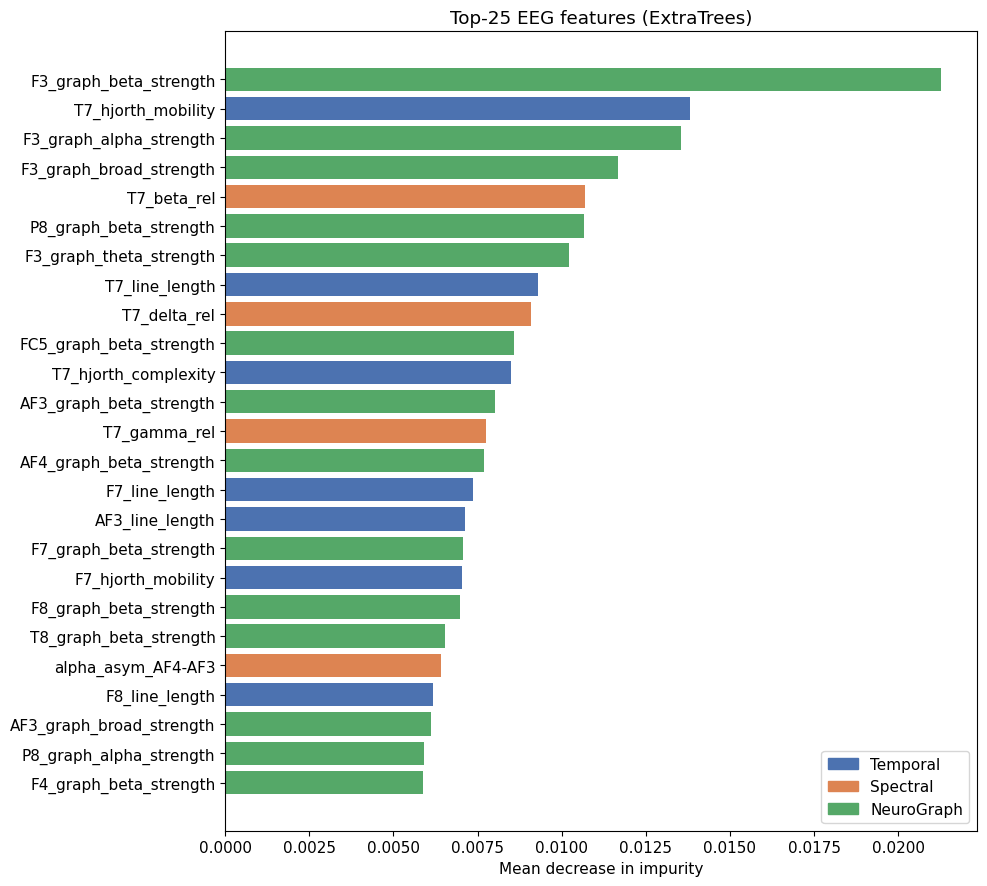

In [23]:
# ============================================================
# 23. FIGURE 14 — TOP FEATURE IMPORTANCE
# ============================================================
interp = ExtraTreesClassifier(n_estimators=400, min_samples_leaf=2, class_weight="balanced", random_state=SEED, n_jobs=-1).fit(X, y)
fi = pd.DataFrame({"feature": FEATURE_NAMES, "group": FEATURE_GROUP, "channel": FEATURE_CHANNEL,
                   "importance": interp.feature_importances_}).sort_values("importance", ascending=False)
fi.to_csv(f"{OUT}/T10_feature_importance.csv", index=False); display(fi.head(20))
top = fi.head(25).iloc[::-1]
gcol = {"Temporal": "#4C72B0", "Spectral": "#DD8452", "NeuroGraph": "#55A868"}
plt.figure(figsize=(10, 9))
plt.barh(top.feature, top.importance, color=[gcol[g] for g in top.group])
plt.legend(handles=[Patch(color=c, label=g) for g, c in gcol.items()]); plt.xlabel("Mean decrease in impurity")
plt.title("Top-25 EEG features (ExtraTrees)")
savefig("Fig14_top_features.png")

,mean,std
group,,
family:NeuroGraph,0.0482,0.0584
ch:T7,0.0423,0.0434
band:beta,0.0376,0.0324
ch:F3,0.0225,0.0727
family:Temporal,0.0180,0.0181
family:Spectral,0.0157,0.0250
ch:F8,0.0105,0.0065
band:delta,0.0092,0.0105
band:alpha,0.0084,0.0131


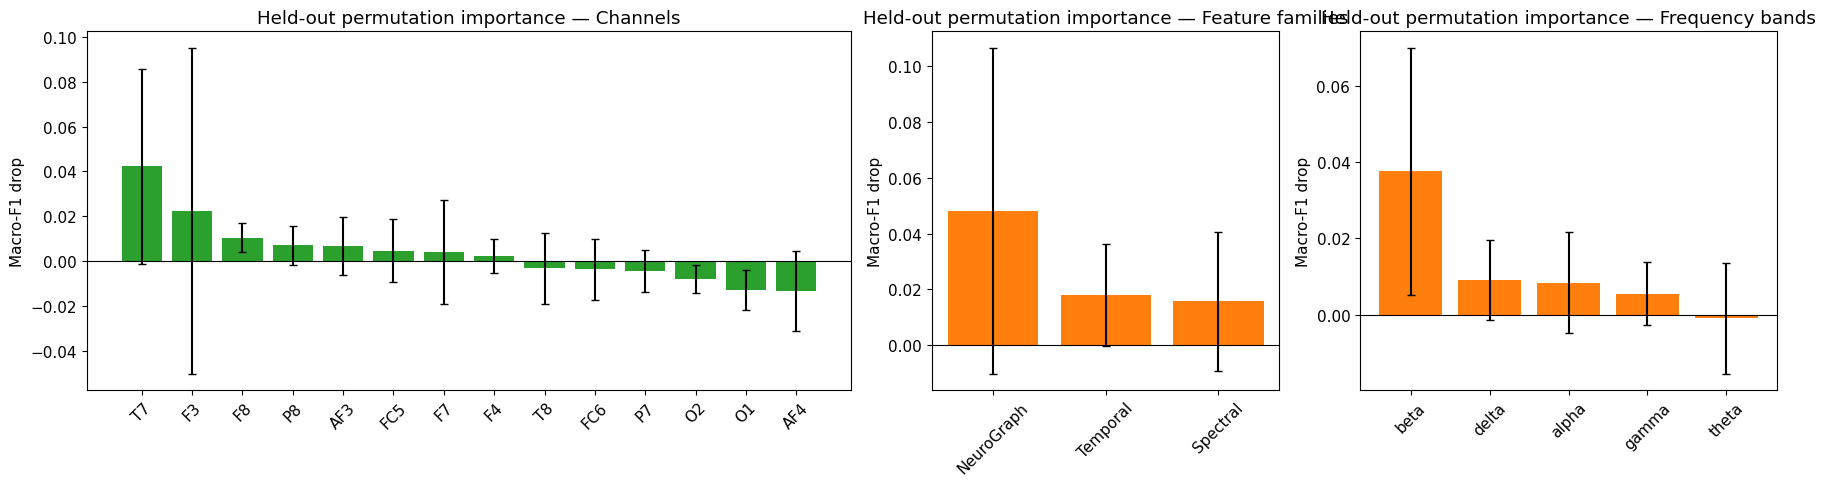

In [24]:
# ============================================================
# 24. GROUPED PERMUTATION IMPORTANCE ON HELD-OUT SUBJECTS
# ============================================================
perm_groups = {f"ch:{c}": np.where(FEATURE_CHANNEL == c)[0] for c in CHANNELS}
perm_groups.update({f"family:{g}": np.where(FEATURE_GROUP == g)[0] for g in ["Temporal", "Spectral", "NeuroGraph"]})
perm_groups.update({f"band:{b}": np.array([i for i, n in enumerate(FEATURE_NAMES) if f"_{b}_rel" in n or f"graph_{b}_" in n])
                    for b in BANDS})
perm_groups = {k: v for k, v in perm_groups.items() if len(v)}
rng = np.random.default_rng(SEED); pi_rows = []
for fold, (tr, te) in enumerate(FOLDS, 1):
    m = fast_et().fit(X[tr], y[tr]); Xte = X[te]
    base = f1_score(y[te], m.predict(Xte), average="macro")
    for gname, cols in perm_groups.items():
        drops = []
        for _ in range(3):
            Xp = Xte.copy(); Xp[:, cols] = Xte[rng.permutation(len(Xte))][:, cols]
            drops.append(base - f1_score(y[te], m.predict(Xp), average="macro"))
        pi_rows.append({"group": gname, "fold": fold, "f1_drop": np.mean(drops)})
pi_df = pd.DataFrame(pi_rows).groupby("group")["f1_drop"].agg(["mean", "std"]).sort_values("mean", ascending=False)
display(pi_df.round(4)); pi_df.to_csv(f"{OUT}/T11_grouped_permutation_importance.csv")

fig, axes = plt.subplots(1, 3, figsize=(18, 5), gridspec_kw={"width_ratios": [2.2, 1, 1.2]})
for ax, prefix, title in [(axes[0], "ch:", "Channels"), (axes[1], "family:", "Feature families"), (axes[2], "band:", "Frequency bands")]:
    sub = pi_df[pi_df.index.str.startswith(prefix)]
    ax.bar(sub.index.str.replace(prefix, ""), sub["mean"], yerr=sub["std"], capsize=3, color="C2" if prefix == "ch:" else "C1")
    ax.axhline(0, color="k", lw=0.8); ax.set_title(f"Held-out permutation importance — {title}"); ax.set_ylabel("Macro-F1 drop")
    ax.tick_params(axis="x", rotation=45)
savefig("Fig15_grouped_permutation_importance.png")

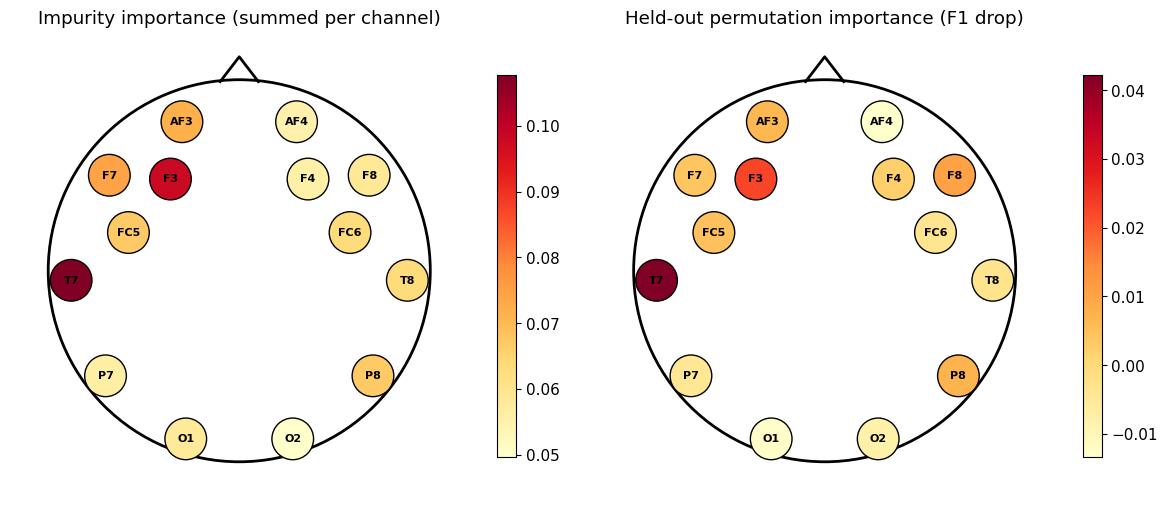

In [25]:
# ============================================================
# 25. FIGURE 16 — SCALP MAP OF CHANNEL IMPORTANCE (Emotiv EPOC 14-ch)
# ============================================================
POS = {"AF3": (-0.30, 0.78), "AF4": (0.30, 0.78), "F7": (-0.68, 0.50), "F8": (0.68, 0.50), "F3": (-0.36, 0.48),
       "F4": (0.36, 0.48), "FC5": (-0.58, 0.20), "FC6": (0.58, 0.20), "T7": (-0.88, -0.05), "T8": (0.88, -0.05),
       "P7": (-0.70, -0.55), "P8": (0.70, -0.55), "O1": (-0.28, -0.88), "O2": (0.28, -0.88)}
ch_imp = fi[fi.channel.isin(CHANNELS)].groupby("channel")["importance"].sum().reindex(CHANNELS)
ch_perm = pi_df.loc[[f"ch:{c}" for c in CHANNELS], "mean"].values
fig, axes = plt.subplots(1, 2, figsize=(12, 5.8))
for ax, vals, title in [(axes[0], ch_imp.values, "Impurity importance (summed per channel)"),
                        (axes[1], ch_perm, "Held-out permutation importance (F1 drop)")]:
    ax.add_patch(plt.Circle((0, 0), 1, fill=False, lw=2)); ax.plot([-0.1, 0, 0.1], [0.99, 1.12, 0.99], "k", lw=2)
    xy = np.array([POS[c] for c in CHANNELS])
    sc = ax.scatter(xy[:, 0], xy[:, 1], c=vals, s=900, cmap="YlOrRd", edgecolor="k")
    for c, (px, py) in zip(CHANNELS, xy): ax.text(px, py, c, ha="center", va="center", fontsize=8, weight="bold")
    ax.set_xlim(-1.2, 1.2); ax.set_ylim(-1.2, 1.25); ax.set_aspect("equal"); ax.axis("off"); ax.set_title(title)
    plt.colorbar(sc, ax=ax, shrink=0.7)
savefig("Fig16_scalp_channel_importance.png")

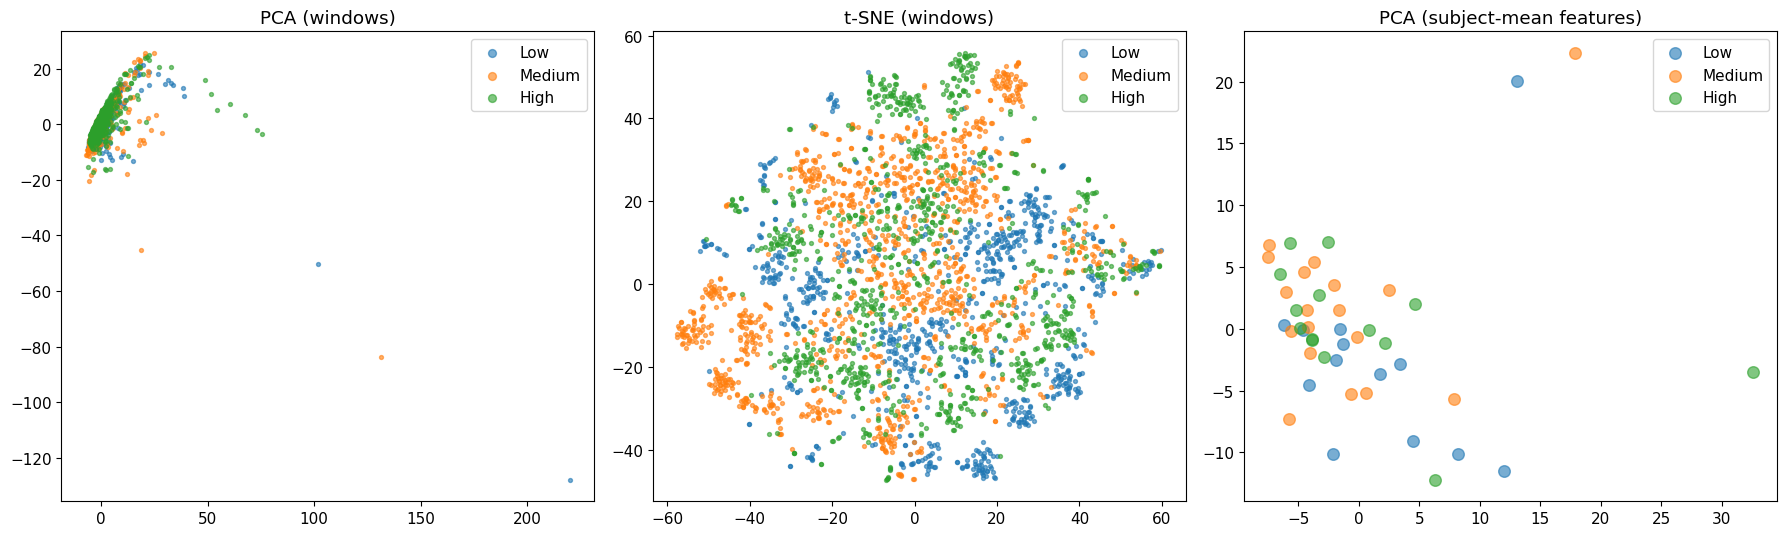

In [26]:
# ============================================================
# 26. FIGURE 17 — PCA / t-SNE OF SUBJECT-LEVEL AND WINDOW-LEVEL FEATURES
# ============================================================
rng = np.random.default_rng(SEED)
idx = rng.choice(len(X), size=min(3000, len(X)), replace=False)
Xs = StandardScaler().fit_transform(X[idx])
Z_pca = PCA(n_components=2, random_state=SEED).fit_transform(Xs)
Z_tsne = TSNE(n_components=2, perplexity=30, init="pca", learning_rate="auto", random_state=SEED).fit_transform(Xs)
Xsub = pd.DataFrame(X).groupby(groups).mean(); ysub = subj_lab.reindex(Xsub.index).values
Z_sub = PCA(n_components=2, random_state=SEED).fit_transform(StandardScaler().fit_transform(Xsub))
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for ax, Z, yy, title, s in [(axes[0], Z_pca, y[idx], "PCA (windows)", 8), (axes[1], Z_tsne, y[idx], "t-SNE (windows)", 8),
                            (axes[2], Z_sub, ysub, "PCA (subject-mean features)", 70)]:
    for k, nm in enumerate(CLASS_NAMES):
        mk = yy == k; ax.scatter(Z[mk, 0], Z[mk, 1], s=s, alpha=0.6, label=nm)
    ax.set_title(title); ax.legend(markerscale=2 if s < 20 else 1)
savefig("Fig17_embeddings.png")

## 13. Neurophysiological statistics (subject-level, avoids window pseudo-replication)

,variable,test,statistic,p_value,effect_size,Low_median,Low_IQR,Medium_median,Medium_IQR,High_median,High_IQR,q_FDR
0,delta_rel (mean of 14 ch),Kruskal-Wallis,1.3337,0.5133,-0.0159,0.4692,0.0685,0.5094,0.0734,0.4985,0.0905,0.9037
1,theta_rel (mean of 14 ch),Kruskal-Wallis,0.2646,0.8761,-0.0413,0.1565,0.0403,0.1597,0.0088,0.1633,0.0240,0.9340
2,alpha_rel (mean of 14 ch),Kruskal-Wallis,2.0640,0.3563,0.0015,0.1139,0.0415,0.0965,0.0305,0.1039,0.0269,0.8908
3,beta_rel (mean of 14 ch),Kruskal-Wallis,1.3795,0.5017,-0.0148,0.1367,0.0301,0.1224,0.0445,0.1196,0.0477,0.9037
4,gamma_rel (mean of 14 ch),Kruskal-Wallis,0.1365,0.9340,-0.0444,0.0388,0.0118,0.0358,0.0158,0.0366,0.0179,0.9340
5,theta/alpha ratio,Kruskal-Wallis,3.5529,0.1692,0.0370,2.2816,0.2338,2.8145,0.7055,2.4244,0.6852,0.5077
6,frontal alpha asymmetry F4-F3,Kruskal-Wallis,0.5765,0.7496,-0.0339,-0.1041,0.2540,-0.1423,0.3587,-0.1377,0.3773,0.9037
7,graph theta mean connectivity,Kruskal-Wallis,0.8241,0.6623,-0.0280,0.4436,0.0869,0.4340,0.0340,0.4355,0.0656,0.9037
8,graph theta global efficiency,Kruskal-Wallis,0.7462,0.6886,-0.0299,0.4849,0.0767,0.4808,0.0311,0.4805,0.0529,0.9037
9,graph alpha mean connectivity,Kruskal-Wallis,5.8378,0.0540,0.0914,0.4809,0.0672,0.4443,0.0482,0.4522,0.0673,0.3797


Effect size: epsilon² for Kruskal-Wallis (3+ classes), rank-biserial r for Mann-Whitney (2 classes).


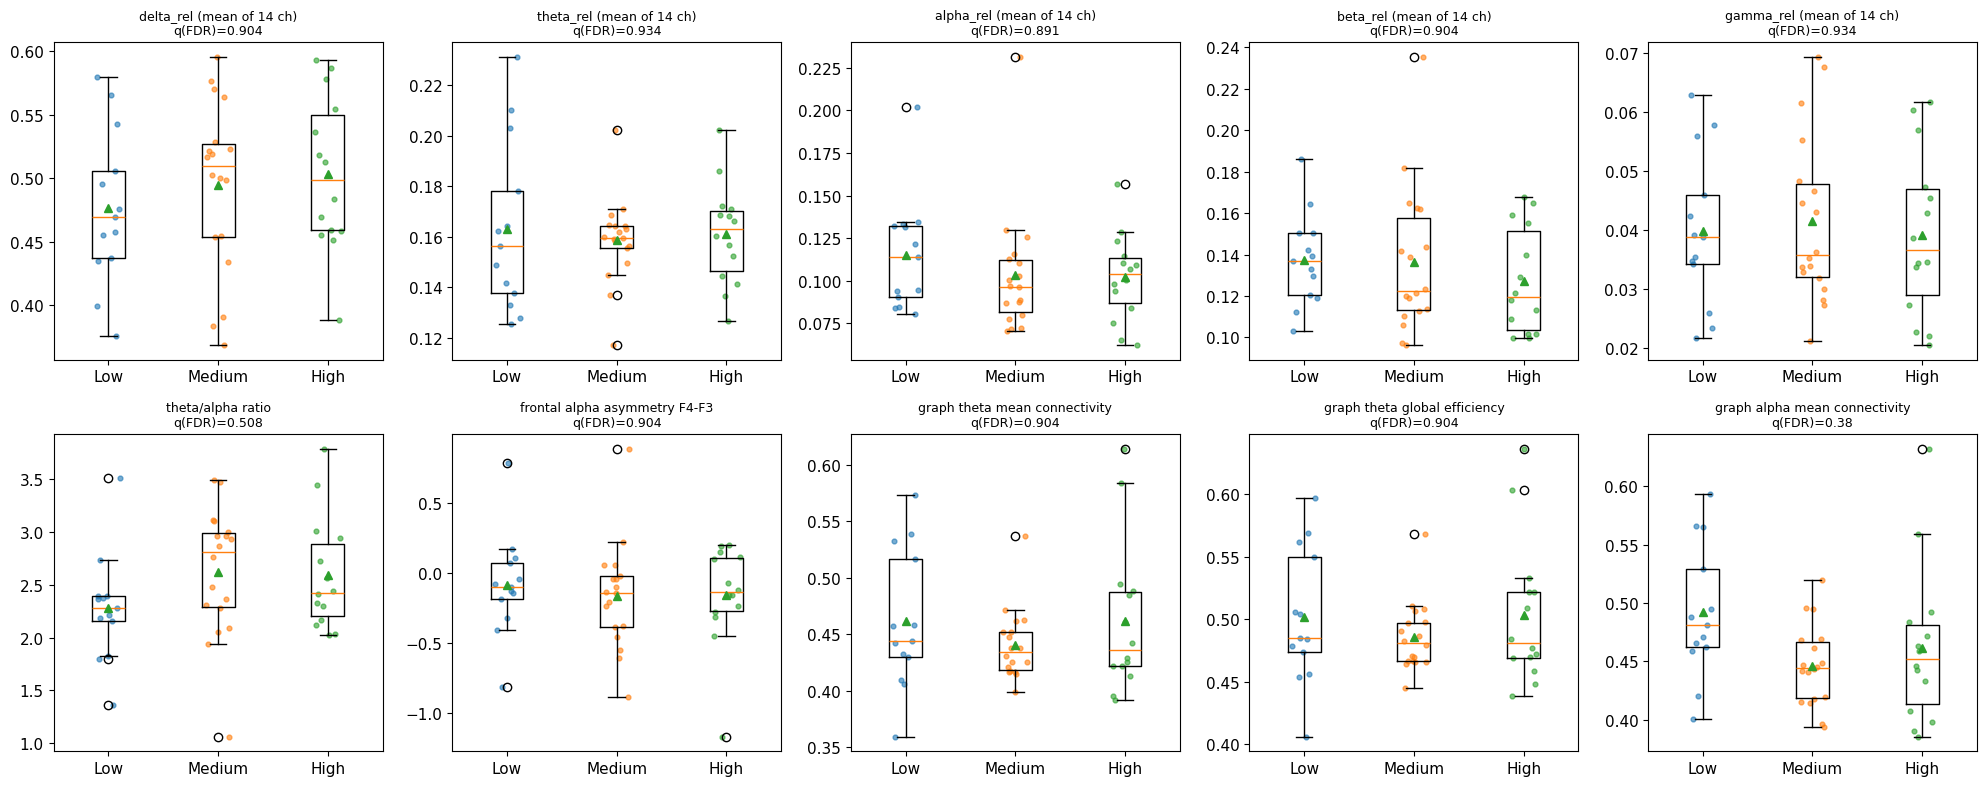

In [27]:
# ============================================================
# 27. BAND POWER / GRAPH METRICS BY CLASS — KRUSKAL-WALLIS / MANN-WHITNEY + FDR
# ============================================================
def bh_fdr(p):
    p = np.asarray(p, float); n = len(p); o = np.argsort(p)
    q = np.empty(n); q[o] = np.minimum.accumulate((p[o] * n / np.arange(1, n + 1))[::-1])[::-1]
    return np.minimum(q, 1)

subj_feat = pd.DataFrame(X, columns=FEATURE_NAMES).groupby(groups).mean()
subj_feat["label"] = subj_lab.reindex(subj_feat.index).values
summary_vars = {}
for b in BANDS:
    summary_vars[f"{b}_rel (mean of 14 ch)"] = subj_feat[[f"{c}_{b}_rel" for c in CHANNELS]].mean(1)
summary_vars["theta/alpha ratio"] = subj_feat[[f"{c}_theta_alpha_ratio" for c in CHANNELS]].mean(1)
summary_vars["frontal alpha asymmetry F4-F3"] = subj_feat["alpha_asym_F4-F3"]
for gb in GRAPH_SETS:
    summary_vars[f"graph {gb} mean connectivity"] = subj_feat[f"graph_{gb}_mean_conn"]
    summary_vars[f"graph {gb} global efficiency"] = subj_feat[f"graph_{gb}_global_eff"]
sv = pd.DataFrame(summary_vars); sv["label"] = subj_feat["label"]

stat_rows = []
for col in sv.columns.drop("label"):
    samples = [sv.loc[sv.label == k, col].dropna().values for k in CLASSES]
    if N_CLASSES > 2:
        h, p = stats.kruskal(*samples); nobs = sum(map(len, samples))
        eff = (h - N_CLASSES + 1) / (nobs - N_CLASSES); test = "Kruskal-Wallis"
    else:
        h, p = stats.mannwhitneyu(*samples, alternative="two-sided"); eff = 1 - 2 * h / (len(samples[0]) * len(samples[1])); test = "Mann-Whitney"
    row = {"variable": col, "test": test, "statistic": h, "p_value": p, "effect_size": eff}
    for k, nm in enumerate(CLASSES):
        row[f"{CLASS_NAMES[k]}_median"] = np.median(samples[k]); row[f"{CLASS_NAMES[k]}_IQR"] = stats.iqr(samples[k])
    stat_rows.append(row)
stat_df = pd.DataFrame(stat_rows); stat_df["q_FDR"] = bh_fdr(stat_df.p_value)
display(stat_df.round(4)); stat_df.to_csv(f"{OUT}/T12_subject_level_statistics.csv", index=False)
print("Effect size: epsilon² for Kruskal-Wallis (3+ classes), rank-biserial r for Mann-Whitney (2 classes).")

show = list(sv.columns.drop("label"))[:10]
fig, axes = plt.subplots(2, 5, figsize=(20, 8)); axes = axes.ravel()
for ax, col in zip(axes, show):
    data = [sv.loc[sv.label == k, col].values for k in CLASSES]
    ax.boxplot(data, showmeans=True); ax.set_xticks(range(1, N_CLASSES + 1)); ax.set_xticklabels(CLASS_NAMES)
    for k, d in enumerate(data): ax.scatter(np.full(len(d), k + 1) + rng.uniform(-0.12, 0.12, len(d)), d, s=12, alpha=0.6)
    q = stat_df.set_index("variable").loc[col, "q_FDR"]; ax.set_title(f"{col}\nq(FDR)={q:.3g}", fontsize=9)
for ax in axes[len(show):]: ax.axis("off")
savefig("Fig18_subject_level_band_graph_stats.png")

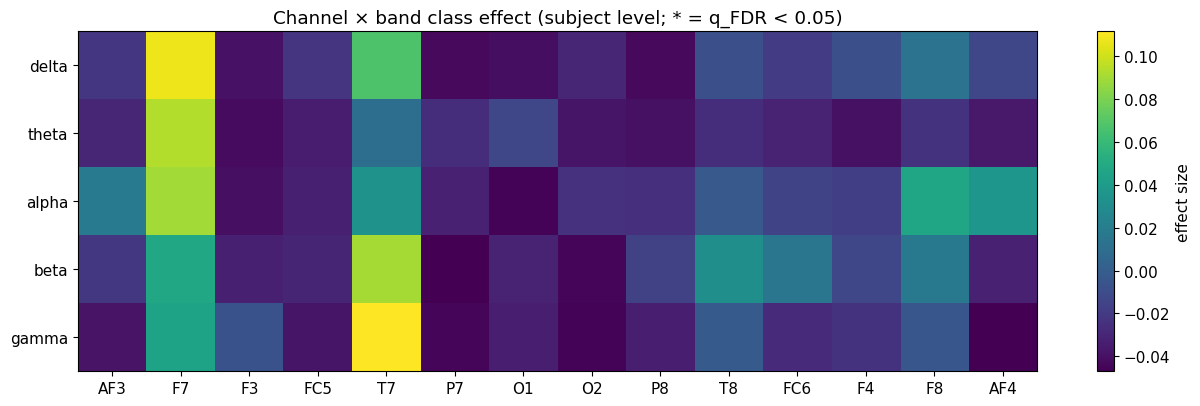

,variable,spearman_rho,p_value,q_FDR
0,delta_rel (mean of 14 ch),0.1262,0.4088,0.6504
1,theta_rel (mean of 14 ch),0.0647,0.6726,0.7761
2,alpha_rel (mean of 14 ch),-0.1049,0.4928,0.6504
3,beta_rel (mean of 14 ch),-0.1436,0.3467,0.6504
4,gamma_rel (mean of 14 ch),-0.0157,0.9185,0.9185
5,theta/alpha ratio,0.1591,0.2964,0.6504
6,frontal alpha asymmetry F4-F3,0.0507,0.7410,0.7939
7,graph theta mean connectivity,-0.1017,0.5063,0.6504
8,graph theta global efficiency,-0.0984,0.5203,0.6504
9,graph alpha mean connectivity,-0.2991,0.0460,0.1935


In [28]:
# ============================================================
# 28. FIGURE 19 — CHANNEL x BAND EFFECT MAP  (+ rating correlation)
# ============================================================
eff_map = np.zeros((len(BANDS), N_CHANNELS)); q_map = np.zeros_like(eff_map); pvals = []
for i, b in enumerate(BANDS):
    for j, c in enumerate(CHANNELS):
        smp = [subj_feat.loc[subj_feat.label == k, f"{c}_{b}_rel"].values for k in CLASSES]
        if N_CLASSES > 2:
            h, p = stats.kruskal(*smp); eff_map[i, j] = (h - N_CLASSES + 1) / (sum(map(len, smp)) - N_CLASSES)
        else:
            h, p = stats.mannwhitneyu(*smp); eff_map[i, j] = 1 - 2 * h / (len(smp[0]) * len(smp[1]))
        pvals.append(p)
q_map = bh_fdr(pvals).reshape(eff_map.shape)
plt.figure(figsize=(13, 4.2))
plt.imshow(eff_map, cmap="RdBu_r" if N_CLASSES == 2 else "viridis", aspect="auto")
plt.colorbar(label="effect size")
for i in range(len(BANDS)):
    for j in range(N_CHANNELS):
        if q_map[i, j] < 0.05: plt.text(j, i, "*", ha="center", va="center", color="w", fontsize=14)
plt.xticks(range(N_CHANNELS), CHANNELS); plt.yticks(range(len(BANDS)), list(BANDS))
plt.title("Channel × band class effect (subject level; * = q_FDR < 0.05)")
savefig("Fig19_channel_band_effect_map.png")
pd.DataFrame(eff_map, index=list(BANDS), columns=CHANNELS).to_csv(f"{OUT}/T13_channel_band_effect_size.csv")

if "rating" in meta:
    rt = meta.drop_duplicates("subject").set_index("subject")["rating"].reindex(sv.index)
    corr_rows = [{"variable": c, **dict(zip(["spearman_rho", "p_value"], stats.spearmanr(sv[c], rt, nan_policy="omit")))}
                 for c in sv.columns.drop("label")]
    corr_df = pd.DataFrame(corr_rows); corr_df["q_FDR"] = bh_fdr(corr_df.p_value)
    display(corr_df.round(4)); corr_df.to_csv(f"{OUT}/T14_rating_correlations.csv", index=False)

## 14. Export all tables, figures and a results summary

In [29]:
# ============================================================
# 29. EXCEL WORKBOOK + JSON SUMMARY + ZIP
# ============================================================
excel_path = f"{OUT}/STEW_NeuroGraph_results.xlsx"
sheets = {"MatInventory": mat_inventory, "Recordings": meta, "FeatureSummary": feature_summary, "FoldResults": results_df,
          "ModelSummary": pretty.reset_index(), "PooledMetricsCI": ci_df, "ModelTests": cmp_df, "Ablation": abl_sum.reset_index(),
          "FeatureImportance": fi, "PermImportance": pi_df.reset_index(), "SubjectOOF": subject_oof, "SubjectStats": stat_df}
if "corr_df" in globals(): sheets["RatingCorrelations"] = corr_df
try:
    with pd.ExcelWriter(excel_path) as w:
        for nm, df in sheets.items(): df.to_excel(w, sheet_name=nm[:31], index=False)
    print("Excel:", excel_path)
except Exception as exc:
    print("Excel export skipped:", exc)

summary = {"task_mode": mode, "classes": CLASS_NAMES, "n_subjects": int(len(np.unique(groups))), "n_windows": int(len(y)),
           "n_features": len(FEATURE_NAMES), "cv": f"{n_splits}-fold StratifiedGroupKFold (subject-wise)",
           "best_model": best_name, "best_model_fold_mean": {m: float(model_summary.loc[best_name, f"{m}_mean"]) for m in metric_cols},
           "permutation_test": {"observed_f1_ET": float(obs_f1), "p_value": float(p_perm), "n_perm": N_PERMUTATIONS},
           "friedman": {"chi2": float(fr.statistic), "p": float(fr.pvalue)}}
json.dump(summary, open(f"{OUT}/results_summary.json", "w"), indent=2)
print(json.dumps(summary, indent=2))

zip_path = f"{OUT}.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for p in sorted(Path(OUT).glob("*")): z.write(p, p.name)
print("\nFiles generated:", len(list(Path(OUT).glob('*'))))
for p in sorted(Path(OUT).glob("*")): print("  ", p.name)
try:
    from google.colab import files
    files.download(zip_path)
except Exception:
    print("Zip archive:", zip_path)

Excel: /content/STEW_NeuroGraph_outputs/STEW_NeuroGraph_results.xlsx
{
  "task_mode": "three_class",
  "classes": [
    "Low",
    "Medium",
    "High"
  ],
  "n_subjects": 45,
  "n_windows": 6705,
  "n_features": 281,
  "cv": "5-fold StratifiedGroupKFold (subject-wise)",
  "best_model": "RandomForest",
  "best_model_fold_mean": {
    "accuracy": 0.4086502609992543,
    "balanced_accuracy": 0.436323639075317,
    "precision": 0.4159441827524253,
    "recall_sensitivity": 0.436323639075317,
    "specificity": 0.7163508043038245,
    "f1": 0.373236408103766,
    "mcc": 0.1491223464949668,
    "kappa": 0.13105440144420408,
    "auc": 0.6379749541764766,
    "pr_auc": 0.4301630636105728,
    "subject_accuracy": 0.4444444444444445
  },
  "permutation_test": {
    "observed_f1_ET": 0.37431769882725896,
    "p_value": 0.09523809523809523,
    "n_perm": 20
  },
  "friedman": {
    "chi2": 5.657142857142858,
    "p": 0.46267091359370405
  }
}

Files generated: 36
   Fig01_class_rating_distribut

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>